In 1952, Peterson and Barney (PB) published [_Control Methods Used in a Study of the Vowels_](https://www.ee.columbia.edu/~dpwe/papers/PetB52-vowels.pdf), in which they "investigate in a general way the relationship between the vowel phoneme intended by a speaker and that identified by a listener, and ... relate these in turn to acoustical measurements of the formant or energy concentration positions in the sound waves." [2].

In 1995, Hillenbrand, Getty, Clark, and Wheeler (HGCW) attempted to reproduce and extend this study, identifying numerous discrepancies between their measurements and those of PB [1]. Critically for us, they observe that "vowels can be separated with a high degree of accuracy if duration and spectral change information is included".

We'll build classifiers to test this claim against the [readily available HGCW data](https://github.com/santiagobarreda/hillenbrand_et_al_1995), reviewing:

- Logistic regression
- Neural Networks
- Convolutional Neural Networks

In [131]:
# styling
from theme.plotting import use, title, PALETTE, CYCLE, TOKENS
use()

{'figure.facecolor': '#fdfcfa',
 'axes.facecolor': '#fdfcfa',
 'savefig.facecolor': '#fdfcfa',
 'savefig.transparent': False,
 'figure.dpi': 150,
 'savefig.dpi': 200,
 'savefig.bbox': 'tight',
 'figure.figsize': (7.0, 4.0),
 'figure.constrained_layout.use': True,
 'font.family': 'sans-serif',
 'font.sans-serif': ['Inter', 'Avenir Next', 'Helvetica Neue', 'DejaVu Sans'],
 'font.serif': ['Cormorant Garamond', 'Georgia', 'DejaVu Serif'],
 'font.monospace': ['JetBrains Mono',
  'JetBrainsMono Nerd Font Mono',
  'DejaVu Sans Mono'],
 'font.size': 10.0,
 'axes.titlesize': 15.0,
 'axes.titleweight': 'semibold',
 'axes.titlelocation': 'left',
 'axes.titlepad': 10,
 'axes.labelsize': 10.0,
 'xtick.labelsize': 9.0,
 'ytick.labelsize': 9.0,
 'legend.fontsize': 9.0,
 'text.color': '#4a4843',
 'axes.labelcolor': '#4a4843',
 'axes.titlecolor': '#0f0f0e',
 'xtick.color': '#807d74',
 'ytick.color': '#807d74',
 'axes.edgecolor': '#e5d9c5',
 'axes.linewidth': 0.8,
 'axes.spines.top': False,
 'axes.spine

## Ingest & EDA

In [132]:
import glob
import os
import IPython.display as ipd

In [133]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import librosa as lb
import scipy as sp
import scipy.signal
import seaborn as sns
import sounddevice as sd
import torch
import torchaudio

The Hillenbrand dataset consists of ...

The data is structured as follows:

- TODO: Explain each file

In [134]:
!ls -l data/hillenbrand

total 42776
-rw-r--r--    1 peleke  staff   117590 Sep 28 16:22 iddata.dat
drwxr-xr-x  554 peleke  staff    17728 Sep 28 16:22 kids
-rw-r--r--    1 peleke  staff  7360580 Sep 28 16:22 kids.zip
drwxr-xr-x  542 peleke  staff    17344 Sep 28 16:22 men
-rw-r--r--    1 peleke  staff  6262970 Sep 28 16:22 men.zip
-rw-r--r--    1 peleke  staff     2376 Sep 28 16:22 misid.dat
-rw-r--r--    1 peleke  staff     2437 Sep 28 16:22 readme.txt
-rw-r--r--    1 peleke  staff    65244 Sep 28 16:22 timedata.dat
-rw-r--r--    1 peleke  staff   136111 Sep 28 16:22 vowdata.dat
drwxr-xr-x  578 peleke  staff    18496 Sep 28 16:22 women
-rw-r--r--    1 peleke  staff  7935697 Sep 28 16:22 women.zip


Audio data is split across three categories, with separate subdirectories for each: men, women, and children.

Each directory contains WAV files, so we can manipulate the raw audio.

In [135]:
!ls -l data/hillenbrand/kids | head -n 5

total 21960
-rw-rw-rw-  1 peleke  staff  13400 May 13  2002 b01ae.wav
-rw-rw-rw-  1 peleke  staff  12728 May 13  2002 b01ah.wav
-rw-rw-rw-  1 peleke  staff  14574 May 13  2002 b01aw.wav
-rw-rw-rw-  1 peleke  staff  14284 May 13  2002 b01eh.wav
ls: stdout: Broken pipe


There is also tabular data; consisting of the following:

- `vowdata.dat`: Contains vowel duration, plus formant frequency measurements: F0 and F1–F4 at steady state, and F1–F3 at 20%, 50%, and 80% of vowel duration.
- `iddata.dat`: Contains label data, specifying which vowels listeners assigned to each recording.
- `misid.dat`: A subset of `iddata.dat` that contains vowels misidentified by listeners.
- `timedata.dat`: Identifies the start, end, and steady-state recording times for each row in `vowdata`; `center1` and `center2` refer to the separate times two different listeners measured the formant's steady state.

We'll plan two kinds of models:

- **Classical ML**, via logistic regression on the tabulated formant frequency data
- **CNN**, trained on Mel spectrograms generated from each recording.

The classical models will use _only_ the tabular data. Separately, we'll use the raw audio to generate Mel spectrograms for a CNN.

#### Loading Tabular Data

We begin with the tabular data.

- Merge `vowdata`, `iddata`, and `misid`
- Create a PyTorch DataSet to wrap our WAV files
- Load `timedata`, trim excess audio, and generate Mel spectrograms

`vowdata.dat` is a text file. We'll need to parse it manually.

The header contains a description of the file contents, with the data following below:

In [136]:
!head -n 35 data/hillenbrand/vowdata.dat

(c) 1995 James Hillenbrand

Filenames:

character 1:     m=man, w=woman, b=boy, g=girl
characters 2-3:  talker number
characters 4-5:  vowel (ae="had", ah="hod", aw="hawed", eh="head", er="heard",
                        ei="haid", ih="hid", iy="heed", oa=/o/ as in "boat",
                        oo="hood", uh="hud", uw="who'd")

col1:  filename
col2:  duration in msec
col3:  f0 at "steady state"
col4:  F1 at "steady state"
col5:  F2 at "steady state"
col6:  F3 at "steady state"
col7:  F4 at "steady state"
col8:  F1 at 20% of vowel duration
col9:  F2 at 20% of vowel duration
col10: F3 at 20% of vowel duration
col11: F1 at 50% of vowel duration
col12: F2 at 50% of vowel duration
col13: F3 at 50% of vowel duration
col14: F1 at 80% of vowel duration
col15: F2 at 80% of vowel duration
col16: F3 at 80% of vowel duration

Note: An entry of zero means that the formant was not measurable.

  1    2   3    4    5    6    7    8    9   10    11  12   13    14  15   16
m01ae 323 174  663 2012 265

#### Representing in Code

We start by recording the speaker categories, column names, and vowel mapping into dictionaries.

In [137]:
# speaker category
speaker_categories = {
    'm': 'man',
    'w': 'woman',
    'b': 'boy',
    'g': 'girl',
}

In [138]:
columns = [
    'filename',
    'duration_ms',
    'f0_ss',
    'f1_ss',
    'f2_ss',
    'f3_ss',
    'f4_ss',
    'f1_20',
    'f2_20',
    'f3_20',
    'f1_50',
    'f2_50',
    'f3_50',
    'f1_80',
    'f2_80',
    'f3_80',
]

In [139]:
# vowel inventory: vowel, IPA
vowels_map = {
    'ae': 'æ',
    'ah': 'ɑ',
    'aw': 'ɔ',
    'eh': 'ɛ',
    'er': 'ɝ',
    'ei': 'e',
    'ih': 'ɪ',
    'iy': 'i',
    'oa': 'o',
    'oo': 'ʊ',
    'uh': 'ʌ',
    'uw': 'u',
}

The HGCW data are collected from speakers of American English; the IPA below should be reasonably accurate, but consider it approximate—HGCW did not provide these equivalences themselves.

| Code | Word | IPA | Description |
| :--- | :--- | :--- | :--- |
| **ae** | had | **/æ/** | Near-open front unrounded vowel |
| **ah** | hod | **/ɑ/** | Open back unrounded vowel |
| **aw** | hawed | **/ɔ/** | Open-mid back rounded vowel |
| **eh** | head | **/ɛ/** | Open-mid front unrounded vowel |
| **er** | heard | **/ɝ/** | R-colored mid central vowel |
| **ei** | haid | **/e/** | Close-mid front vowel (often transcribed as diphthong **/eɪ/**) |
| **ih** | hid | **/ɪ/** | Near-close near-front unrounded vowel |
| **iy** | heed | **/i/** | Close front unrounded vowel |
| **oa** | boat | **/o/** | Close-mid back vowel (often transcribed as diphthong **/oʊ/**) |
| **oo** | hood | **/ʊ/** | Near-close near-back rounded vowel |
| **uh** | hud | **/ʌ/** | Open-mid back unrounded vowel |
| **uw** | who'd | **/u/** | Close back rounded vowel |

[Read this](https://www.researchgate.net/publication/231929195_American_English_Southern_Michigan)

Now, we load `vowdata.dat` into a DataFrame.

In [140]:
df = pd.read_csv(
    'data/hillenbrand/vowdata.dat',
    sep=r"\s+",
    header=None,
    names=columns,
    skiprows=30,
)

In [141]:
df.head()

,filename,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
0,m01ae,323,174,663,2012,2659,3691,669,2008,2671,671,1992,2659,685,1773,2680
1,m02ae,250,102,628,1871,2477,3489,627,1871,2456,636,1881,2455,628,1793,2451
2,m03ae,344,99,605,1812,2570,0,608,1812,2572,618,1789,2618,632,1708,2693
3,m04ae,312,124,627,1910,2488,3463,629,1882,2460,720,1750,2435,757,1563,2527
4,m06ae,254,115,647,1864,2561,3506,642,1866,2557,666,1829,2499,689,1696,2556


We add a `path` column to facilitate working with the raw audio.

In [142]:
paths = []

In [143]:
for filename in df['filename']:
    category = filename[0]
    if category == 'm':
        path = f'data/hillenbrand/men/{filename}'
    elif category in ['b', 'g']:
        path = f'data/hillenbrand/kids/{filename}'
    elif category == 'w':
        path = f'data/hillenbrand/women/{filename}'
    else:
        raise ValueError("huh-what?")
    paths.append(path)

In [144]:
paths[:5]

['data/hillenbrand/men/m01ae',
 'data/hillenbrand/men/m02ae',
 'data/hillenbrand/men/m03ae',
 'data/hillenbrand/men/m04ae',
 'data/hillenbrand/men/m06ae']

In [145]:
df['path'] = paths

In [146]:
df.head()

,filename,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80,path
0,m01ae,323,174,663,2012,2659,3691,669,2008,2671,671,1992,2659,685,1773,2680,data/hillenbrand/men/m01ae
1,m02ae,250,102,628,1871,2477,3489,627,1871,2456,636,1881,2455,628,1793,2451,data/hillenbrand/men/m02ae
2,m03ae,344,99,605,1812,2570,0,608,1812,2572,618,1789,2618,632,1708,2693,data/hillenbrand/men/m03ae
3,m04ae,312,124,627,1910,2488,3463,629,1882,2460,720,1750,2435,757,1563,2527,data/hillenbrand/men/m04ae
4,m06ae,254,115,647,1864,2561,3506,642,1866,2557,666,1829,2499,689,1696,2556,data/hillenbrand/men/m06ae


Filenames have structure. For instance: `m01ae` encodes: _"male; speaker ID 01; speaking the vowel 'ae'"_.

We split `filename` into these features.

In [147]:
categories, talker_numbers, vowels = [], [], []

In [148]:
for filename in df['filename']:
    category = categories.append(filename[0])
    talker_number = talker_numbers.append(filename[:3])  # e.g. 'm01'; talker numbers restart per category
    vowel = vowels.append(filename[3:])

In [149]:
df['category'] = categories
df['speaker_id'] = talker_numbers
df['vowel'] = vowels

Let's reorder columns.

In [150]:
metadata_cols = ['filename', 'category', 'speaker_id', 'vowel', 'path']
acoustic_cols = [col for col in columns if col != 'filename']
df = df[metadata_cols + acoustic_cols]

In [151]:
df.head()

,filename,category,speaker_id,vowel,path,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
0,m01ae,m,m01,ae,data/hillenbrand/men/m01ae,323,174,663,2012,2659,3691,669,2008,2671,671,1992,2659,685,1773,2680
1,m02ae,m,m02,ae,data/hillenbrand/men/m02ae,250,102,628,1871,2477,3489,627,1871,2456,636,1881,2455,628,1793,2451
2,m03ae,m,m03,ae,data/hillenbrand/men/m03ae,344,99,605,1812,2570,0,608,1812,2572,618,1789,2618,632,1708,2693
3,m04ae,m,m04,ae,data/hillenbrand/men/m04ae,312,124,627,1910,2488,3463,629,1882,2460,720,1750,2435,757,1563,2527
4,m06ae,m,m06,ae,data/hillenbrand/men/m06ae,254,115,647,1864,2561,3506,642,1866,2557,666,1829,2499,689,1696,2556


Next, we address this note in the metadata:

> Note: An entry of zero means that the formant was not measurable.

I.e., 0 is an explicit indication of a measurement error. Let's see where these occur.

In [152]:
(df == 0).sum()

filename         0
category         0
speaker_id       0
vowel            0
path             0
duration_ms      0
f0_ss            0
f1_ss            0
f2_ss           10
f3_ss           41
f4_ss          243
f1_20            0
f2_20           10
f3_20           39
f1_50            0
f2_50           13
f3_50           46
f1_80            0
f2_80            3
f3_80           41
dtype: int64

In [153]:
len(df)

1668

In [154]:
243 / 1668

0.14568345323741008

Roughly 15% of the steady-state formant 4 data was unmeasurable. Not great, but F4 is poorly represented, anyway; might not be a terrible loss.

Let's mark these as `np.nan` so we don't confuse the model.

In [155]:
df.replace(0, np.nan, inplace=True)

,filename,category,speaker_id,vowel,path,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
0,m01ae,m,m01,ae,data/hillenbrand/men/m01ae,323,174,663,2012.0,2659.0,3691.0,669,2008.0,2671.0,671,1992.0,2659.0,685,1773.0,2680.0
1,m02ae,m,m02,ae,data/hillenbrand/men/m02ae,250,102,628,1871.0,2477.0,3489.0,627,1871.0,2456.0,636,1881.0,2455.0,628,1793.0,2451.0
2,m03ae,m,m03,ae,data/hillenbrand/men/m03ae,344,99,605,1812.0,2570.0,NaN,608,1812.0,2572.0,618,1789.0,2618.0,632,1708.0,2693.0
3,m04ae,m,m04,ae,data/hillenbrand/men/m04ae,312,124,627,1910.0,2488.0,3463.0,629,1882.0,2460.0,720,1750.0,2435.0,757,1563.0,2527.0
4,m06ae,m,m06,ae,data/hillenbrand/men/m06ae,254,115,647,1864.0,2561.0,3506.0,642,1866.0,2557.0,666,1829.0,2499.0,689,1696.0,2556.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1663,g17uw,g,g17,uw,data/hillenbrand/kids/g17uw,245,236,490,2179.0,3131.0,4420.0,482,2163.0,3097.0,491,2044.0,3097.0,500,1912.0,3056.0
1664,g18uw,g,g18,uw,data/hillenbrand/kids/g18uw,315,214,435,1829.0,3316.0,4536.0,432,1836.0,3378.0,435,1684.0,3276.0,444,1716.0,3229.0
1665,g19uw,g,g19,uw,data/hillenbrand/kids/g19uw,192,243,497,1334.0,3067.0,3928.0,491,1335.0,3067.0,492,1402.0,3044.0,478,1490.0,2961.0
1666,g20uw,g,g20,uw,data/hillenbrand/kids/g20uw,248,248,498,1740.0,3291.0,4500.0,496,1728.0,3327.0,467,1665.0,3312.0,450,1821.0,3383.0


We need to do preprocessing and such—specifically, normalize duration and formant frequencies—but this is ready to prepare for our classical classification models.

#### Loading `iddata` and `misid`

Next, we load labels.

In [156]:
!head -n 21 data/hillenbrand/iddata.dat

col1 = Filename
col2 = Percent correct ID
col3 = Number (out of 20) heard as iy
col4 = Number (out of 20) heard as ih
col5 = Number (out of 20) heard as ei
col6 = Number (out of 20) heard as eh
col7 = Number (out of 20) heard as ae
col8 = Number (out of 20) heard as ah
col9 = Number (out of 20) heard as aw
col10= Number (out of 20) heard as oa
col11= Number (out of 20) heard as oo
col12= Number (out of 20) heard as uw
col13= Number (out of 20) heard as uh
col14= Number (out of 20) heard as er
col15= Signal heard predominately as this vowel

Note: An asterisk to the far right means that the majority vote was
      for a vowel other than that intended by the talker.

Filename    %ID   iy  ih  ei  eh  ae  ah  aw  oa  oo  uw  uh  er Vote
m01ae.w     95.0   0   0   0   1  19   0   0   0   0   0   0   0  ae


In [157]:
columns_iddata = [
    'filename',
    '%_id',
    'iy',
    'ih',
    'ei',
    'eh',
    'ae',
    'ah',
    'aw',
    'oa',
    'oo',
    'uw',
    'uh',
    'er',
    'vote',
    'misid',
]

In [158]:
df_iddata = pd.read_csv(
    'data/hillenbrand/iddata.dat',
    sep=r"\s+",
    header=None,
    names=columns_iddata,
    skiprows=20,
)

Each row shows how many votes each vowel received from listeners during labeling. Each token was labeled by 20 listeners (one, `g12eh`, has 19 votes).

In [159]:
df_iddata.head()

,filename,%_id,iy,ih,ei,eh,ae,ah,aw,oa,oo,uw,uh,er,vote,misid
0,m01ae.w,95.0,0,0,0,1,19,0,0,0,0,0,0,0,ae,NaN
1,m01ah.w,95.0,0,0,0,0,0,19,1,0,0,0,0,0,ah,NaN
2,m01aw.w,95.0,0,0,0,0,0,1,19,0,0,0,0,0,aw,NaN
3,m01eh.w,100.0,0,0,0,20,0,0,0,0,0,0,0,0,eh,NaN
4,m01ei.w,100.0,0,0,20,0,0,0,0,0,0,0,0,0,ei,NaN


In [160]:
df_iddata.describe()['%_id']

count    1668.000000
mean       94.640288
std        12.425765
min         0.000000
25%        95.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: %_id, dtype: float64

Listeners agree across most of our rows.

Convert `misid` to a boolean column, so it's `False` if there's no asterisk (instead of `NaN`) and `True` otherwise.

In [161]:
df_iddata['misid'] = df_iddata['misid'].notna()

Next, we load data corresponding to misidentified vowels; these are instances of vowels that listeners guessed wrong.

In [162]:
!head -n 5 data/hillenbrand/misid.dat

m04eh.w     30.0   0   0   0   6  14   0   0   0   0   0   0   0  ae *
m16ah.w     25.0   0   0   0   0   0   5   1   0   0   0  14   0  uh *
m22aw.w     45.0   0   0   0   0   0  11   9   0   0   0   0   0  ah *
m24aw.w     45.0   0   0   0   0   0  11   9   0   0   0   0   0  ah *
m29aw.w     40.0   0   0   0   1   0  11   8   0   0   0   0   0  ah *


In [163]:
df_misid = pd.read_csv(
    'data/hillenbrand/misid.dat',
    sep=r"\s+",
    header=None,
    names=columns_iddata,
    skiprows=0,
)

In [164]:
df_misid.head()

,filename,%_id,iy,ih,ei,eh,ae,ah,aw,oa,oo,uw,uh,er,vote,misid
0,m04eh.w,30.0,0,0,0,6,14,0,0,0,0,0,0,0,ae,*
1,m16ah.w,25.0,0,0,0,0,0,5,1,0,0,0,14,0,uh,*
2,m22aw.w,45.0,0,0,0,0,0,11,9,0,0,0,0,0,ah,*
3,m24aw.w,45.0,0,0,0,0,0,11,9,0,0,0,0,0,ah,*
4,m29aw.w,40.0,0,0,0,1,0,11,8,0,0,0,0,0,ah,*


All `misid` values here are `True`, so might as well force that.

In [165]:
df_misid['misid'] = True

We'll use this to guide evaluation of the final model.

#### Creating Labels

Let's convert the `iddata` DataFrame into a proper set of `y` labels.

In [166]:
df_iddata.head()

,filename,%_id,iy,ih,ei,eh,ae,ah,aw,oa,oo,uw,uh,er,vote,misid
0,m01ae.w,95.0,0,0,0,1,19,0,0,0,0,0,0,0,ae,False
1,m01ah.w,95.0,0,0,0,0,0,19,1,0,0,0,0,0,ah,False
2,m01aw.w,95.0,0,0,0,0,0,1,19,0,0,0,0,0,aw,False
3,m01eh.w,100.0,0,0,0,20,0,0,0,0,0,0,0,0,eh,False
4,m01ei.w,100.0,0,0,20,0,0,0,0,0,0,0,0,0,ei,False


In [167]:
subcols = [c for c in df_iddata.columns if c not in ['%_id', 'vote', 'misid', 'filename']]

In [168]:
# listener majority vote, keyed on filename and aligned to df's row order.
# Used to evaluate against human listeners; the training target is the intended vowel (df['vowel']).
votes = df_iddata.set_index(df_iddata['filename'].str.removesuffix('.w'))[subcols]
y_vote = votes.idxmax(axis=1).reindex(df['filename'])

We still need to scale `vowdata`, but we have what we need to prepare the classical classifier.

#### Raw Audio & Mel Spectrograms

Before we grab the audio, let's load `timedata.dat`, which gives us the following data about each recording in milliseconds:

- `start`
- `end`
- `center1` (steady-state vowel time from judge 1)
- `center2` (steady-state vowel time from judge 2)

These will allow us to trim onset and coda from the vowel recordings before generating spectrograms for the CNN.

In [169]:
columns_timedata = [
    'filename',
    'start',
    'end',
    'center1',
    'center2',
]

In [170]:
df_timedata = pd.read_csv(
    'data/hillenbrand/timedata.dat',
    sep=r"\s+",
    header=None,
    names=columns_timedata,
    skiprows=6,
)

In [171]:
df_timedata.head()

,filename,start,end,center1,center2
0,m01ae,177.3,500.4,304.0,297.0
1,m02ae,132.0,382.0,198.0,240.0
2,m03ae,118.0,462.0,162.0,181.0
3,m04ae,96.0,408.0,130.0,169.0
4,m06ae,71.0,325.0,113.0,134.0


We still need to use the raw data to generate Mel spectrograms, but this is enough to facilitate doing so.

Let's do some exploratory data analysis first.

#### Inspecting the Hillenbrand Recordings

Loading the first...

In [172]:
example = df['path'].iloc[0]
example

'data/hillenbrand/men/m01ae'

In [173]:
audio, sr = lb.load(f'{example}.wav', sr=None)

In [174]:
# sampling rate; n.b., can only represent signals up to 8k 
sr

16000

In [175]:
ipd.Audio(audio, rate=sr)

Let's sanity-check the `timedata` contents; we'll plot the waveform and overlay the start/end times.

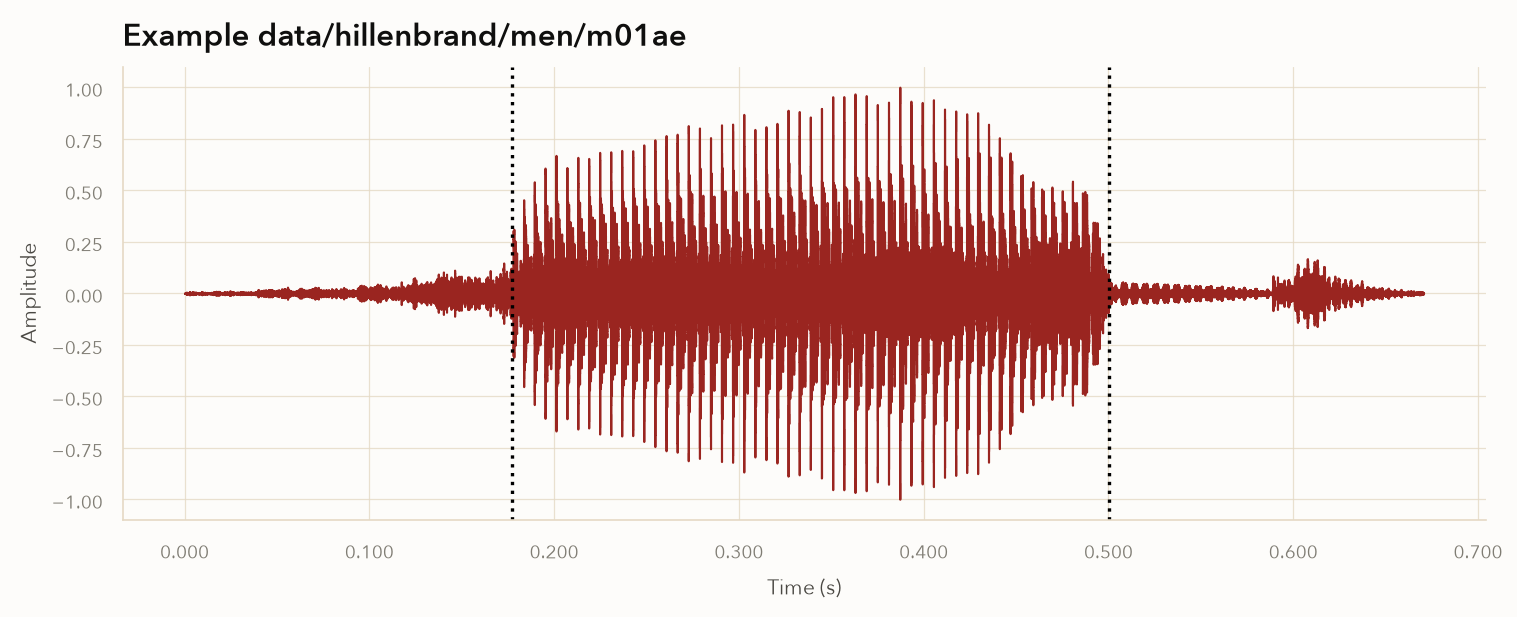

In [176]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 4))
lb.display.waveshow(audio, sr=sr, ax=ax)

# Add labels and show
ax.set(title=f'Example {example}', xlabel="Time (s)", ylabel="Amplitude")
plt.axvline(x=df_timedata['start'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.axvline(x=df_timedata['end'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.show()

This is just the **waveform**; the amplitude of the wave over time. Vertical lines indicate the start and end of the vowel, isolated from onset and coda consonants.

In [177]:
df.columns

Index(['filename', 'category', 'speaker_id', 'vowel', 'path', 'duration_ms',
       'f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss', 'f1_20', 'f2_20', 'f3_20',
       'f1_50', 'f2_50', 'f3_50', 'f1_80', 'f2_80', 'f3_80'],
      dtype='str')

Time data checks out for this row. But amplitude isn't informative.

Let's look at the spectrum.

### Spectral Analysis

We start with a simple FFT for a global image of the frequency domain.

In [178]:
sample_rate = 16000

In [179]:
audio, sr = lb.load(f'{example}.wav', sr=sample_rate)

In [180]:
# chop audio to vowel
start = int(df_timedata.iloc[0]['start'] * sample_rate / 1000)
end = int(df_timedata.iloc[0]['end'] * sample_rate / 1000)
(start, end)

(2836, 8006)

In [181]:
audio_ = audio[start:end]

In [182]:
# real FFT
fft_res = np.fft.rfft(audio_)
# drop phase; we only want amplitudes; and normalize against peak amplitude
fft_mag = (2 / len(audio_)) * np.abs(fft_res)
# map to real frequency bins
fft_freqs = np.fft.rfftfreq(len(audio_), 1.0 / sample_rate)

Text(0, 0.5, 'Amplitude')

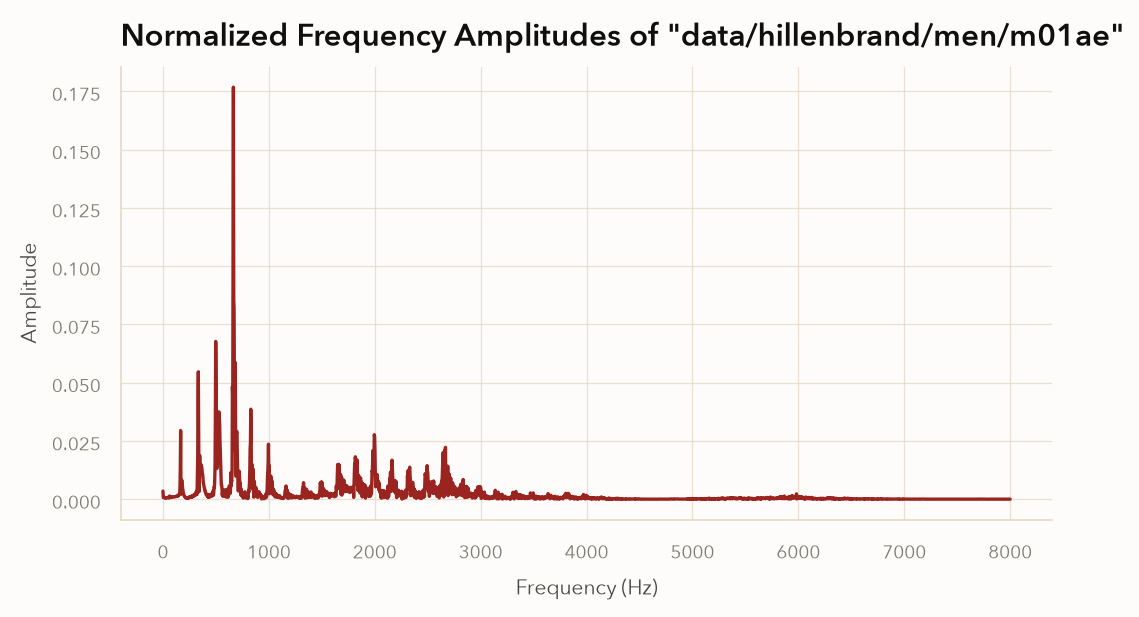

In [183]:
plt.plot(fft_freqs, fft_mag)
plt.title(f'Normalized Frequency Amplitudes of "{example}"')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')

This matches what's in the tabular data; we see a cluster of frequencies roughly around F1, F2, and F3.

In [184]:
def get_formants(df_):
    filtered_columns = [c for c in df.columns if c.startswith('f') and not c.startswith('file')]
    new_ = df_[sorted(filtered_columns, key=lambda x: str(x)[:2])]
    return new_

In [185]:
print(get_formants(df.iloc[0]).to_markdown(index=True))

|       |    0 |
|:------|-----:|
| f0_ss |  174 |
| f1_ss |  663 |
| f1_20 |  669 |
| f1_50 |  671 |
| f1_80 |  685 |
| f2_ss | 2012 |
| f2_20 | 2008 |
| f2_50 | 1992 |
| f2_80 | 1773 |
| f3_ss | 2659 |
| f3_20 | 2671 |
| f3_50 | 2659 |
| f3_80 | 2680 |
| f4_ss | 3691 |


This is more apparent if we plot the power spectrum by squaring `fft_mag`.

Text(0, 0.5, 'Power')

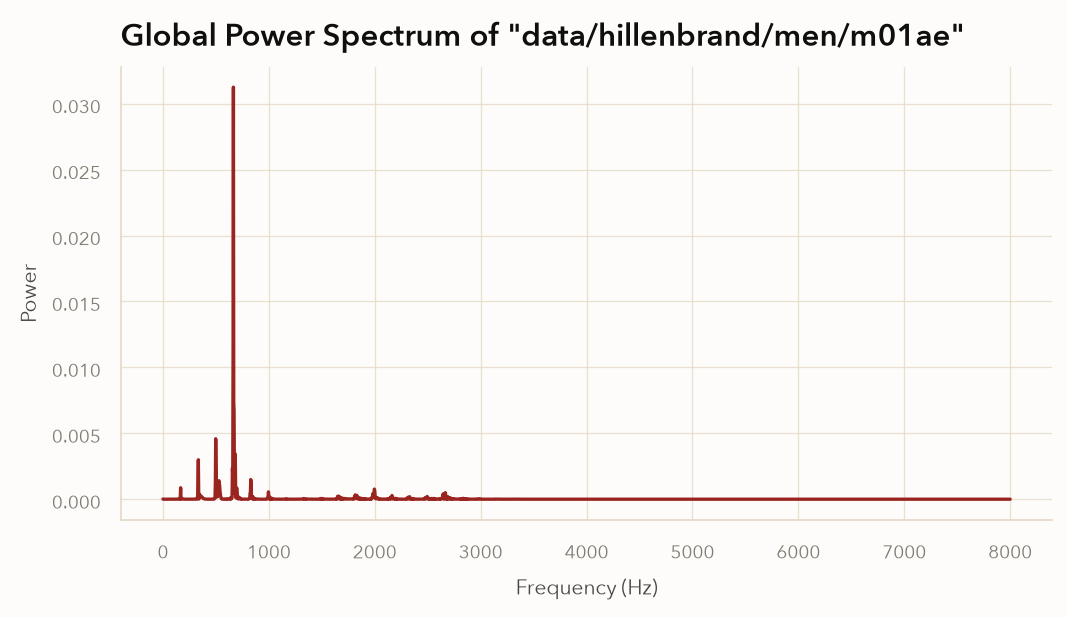

In [186]:
plt.plot(fft_freqs, fft_mag ** 2)
plt.title(f'Global Power Spectrum of "{example}"')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')

The global view contains no information about _dynamics_ so we can't verify the sequencing of SS/20/50/80 measurements this way.

For that, we use the [STFT](https://en.wikipedia.org/wiki/Short-time_Fourier_transform) to compute wideband and narrowband spectrograms.

There are two important time scales in speech analysis:

- **Period of the Fundamental Frequency (F0)**: This is the period of the fundamental frequency, which determines its pitch. Changing F0 does _not_ change the vowel that we perceive, but rather our perception of how high/low it is. F0 is due to the frequency of the pulse train produced by the glottis—i.e., the _source_ of the voice—and _not_ the vocal tract, 
- **Period of First Formant (F1)**: Period of the first formant, i.e., the first vocal tract resonance. Formants are _not_ harmonics of F0; they're resonances that occur within the _vocal tract_, selectively amplifying and attenuating frequencies from the vocal source. Because formants result from the filtering action of the vocal tract, they evolve on a different time scale than the glottal pulse train.

Expressions for these time scales are as follows:

$$
\begin{aligned}
& T_{0} = \frac{1}{F_{0}} \\
& T_{1} = \frac{1}{F_{1}} \\
\end{aligned}
$$

These time scales are speaker-dependent, because the frequency of F0 and F1 depends on the individual, and period is the inverse of frequency. This has material consequences for speakers with higher-frequency F0 values; we'll return to this when discussing normalization.

---

1. Cite: https://courses.grainger.illinois.edu/ece590sip/sp2018/spectrograms1_wideband_narrowband.html

For the speaker in our example, we have the following values for F0 and F1 at steady-state:

In [187]:
f0, f1 = get_formants(df.iloc[0])[['f0_ss', 'f1_ss']]

In [188]:
# period in milliseconds
t0 = 1.0 / f0 * 1000
t1 = 1.0 / f1 * 1000
(t0, t1)

(np.float64(5.747126436781609), np.float64(1.5082956259426847))

In [189]:
1 / t0 * 1000

np.float64(174.00000000000003)

In [190]:
2 / t0 * 1000

np.float64(348.00000000000006)

In [191]:
348 * 4

1392

### Interlude: Window Length and Frequency Resolution

> _Drafted by Claude (Opus 5.5, Anthropic), 2026-11-08, for review. Numbers checked numerically; prose not yet edited._

**Bin spacing.** An STFT frame holds $N$ samples. Its DFT has bins at multiples of $F_{s}/N$. For a window $L$ seconds long, $N = L F_{s}$, so the bins are $1/L$ Hz apart: a longer window means finer bins. Zero-padding the frame to a larger `n_fft` (librosa's default is 2048) samples the same spectrum more densely. It draws a smoother curve but cannot separate anything the original $N$ samples couldn't.

**The window's footprint.** Windowing multiplies the frame by $w[n]$ in time, which convolves its spectrum with $W(f)$ in frequency. Every sinusoid in the frame therefore shows up as a copy of $W(f)$, centred on its frequency. The width of that copy's mainlobe, measured in bins, depends only on the window's shape. In Hz it is that width times $F_{s}/N$, so it shrinks as $1/L$.

| Window | −3 dB width | −6 dB width | Null-to-null |
| :--- | ---: | ---: | ---: |
| Rectangular | 0.89 | 1.21 | 2 |
| Hann (librosa default) | 1.44 | 2.00 | 4 |
| Hamming | 1.30 | 1.82 | 4 |

(Widths in bins, from Harris 1978, Table 1; reproduced numerically with a 64-point FFT zero-padded 512×.)

**Three widths, three questions.**

- **−3 dB width:** how wide a single peak looks (its half-power bandwidth).
- **Null-to-null:** the total footprint of one tone's mainlobe, i.e. how far its energy spreads before the first zero.
- **−6 dB width:** whether two neighbouring tones of equal amplitude appear as two peaks. At the midpoint between them, each mainlobe has fallen by its value at half the spacing. When the spacing equals the −6 dB width, each contributes half its peak amplitude there, and in phase they add back up to roughly peak height: no dip. Wider spacing gives a dip; narrower spacing may or may not, depending on the tones' relative phase. This is the usual resolution criterion.

A check with two equal tones in an 80-sample Hann frame at 16 kHz: between 175 and 350 Hz apart, the spectrum showed one or two peaks depending on the tones' relative phase. At 400 Hz and above, it showed two at every phase tried.

**Where the narrowband/wideband rule comes from.** Harmonics sit $F_{0}$ apart. With Hann, separating them requires $2F_{s}/N < F_{0}$, i.e. $2/L < F_{0}$, i.e. $L > 2T_{0}$: a narrowband window spans at least two pitch periods. A wideband window, $L < T_{0}$, is too short to separate harmonics. They merge into broad formant bands, and the frame is short enough that individual glottal pulses show up as vertical striations.

**Our windows** ($F_{s} = 16$ kHz; example speaker $F_{0} \approx 174$ Hz, $T_{0} \approx 5.75$ ms):

| Window | $N$ | Bin spacing | −3 dB | −6 dB | Harmonics resolved? |
| :--- | ---: | ---: | ---: | ---: | :--- |
| 2.5 ms | 40 | 400 Hz | 576 Hz | 800 Hz | no |
| 5 ms | 80 | 200 Hz | 288 Hz | 400 Hz | no |
| 30 ms | 480 | 33 Hz | 48 Hz | 67 Hz | yes |
| 35 ms | 560 | 29 Hz | 41 Hz | 57 Hz | yes |

**What the window doesn't change.** The frequency range is 0 to $F_{s}/2$ (8 kHz here) for every window length. A short window doesn't reveal higher frequencies; it trades frequency resolution for time resolution. For a fixed window shape, the product of time width and frequency width is constant, so you can only move along that trade-off. The hop length sets how often frames are taken, not how sharp each one is.

> _End Claude_

A **narrowband spectrogram** uses a window longer than two pitch periods, $L > 2T_{0}$; a **wideband spectrogram** uses one shorter than a single period, $L < T_{0}$. Here $L$ is the window length in seconds; in samples, it's $N = L F_{s}$.

Frequency resolution is set by the window length. A DFT over an $N$-sample window has bins spaced $F_{s} / N = 1 / L$ Hz apart. (Zero-padding to a larger `n_fft`, as librosa does by default, interpolates between these bins but doesn't improve resolution.) Windowing spreads each sinusoid into a copy of the window's spectrum, whose mainlobe spans several bins. For the Hann window, librosa's default, the mainlobe is about 1.44 bins wide at −3 dB, 2 bins at −6 dB, and 4 bins null-to-null [7]. In general,

$$
f_{\Delta} = B \cdot \frac{F_{s}}{N}
$$

where $B$ is the relevant width in bins. Two equal-amplitude sinusoids can be told apart when their spacing exceeds the −6 dB width, so for Hann, $f_{\Delta} \approx 2 F_{s} / N = 2 / L$. That is where the rule of thumb comes from: resolving harmonics spaced $F_{0}$ apart requires $2 / L < F_{0}$, i.e. $L > 2 T_{0}$.

For our two windows:

| Window | $N$ | Bin spacing | −3 dB width | −6 dB width |
| :--- | ---: | ---: | ---: | ---: |
| 5 ms (wideband) | 80 | 200 Hz | 288 Hz | 400 Hz |
| 30 ms (narrowband) | 480 | 33 Hz | 48 Hz | 67 Hz |

With $F_{0} \approx 174$ Hz, the 30 ms window resolves individual harmonics (67 Hz < 174 Hz). The 5 ms window doesn't (400 Hz > 174 Hz): harmonics merge into broad formant bands, and in exchange the time resolution is fine enough to show individual glottal pulses.

Common default window lengths for wideband and narrowband spectrograms are often given as ~5 ms and ~30 ms, respectively. These indeed work for our case:

In [192]:
# 5 ms is < t0; 30 ms > 2 * t0
(t0, 2 * t0)

(np.float64(5.747126436781609), np.float64(11.494252873563218))

We configure it via the `win_length` parameter to [librosa.stft](https://librosa.org/doc/main/api/generated/libro.stft.html).

`win_length` expects an `int` corresponding to a number of samples. Our input is `T := len(audio)` samples long, and our sampling rate is 16 kHz. So we compute `win_length` as:

$$
\textrm{wl} = \textrm{int}(0.005 * 16,000) = 80
$$

...And:

$$
\textrm{wl} = \textrm{int}(0.03 * 16,000) = 480
$$

In [193]:
# seconds
win_dur_wb = 5e-3
win_dur_nb = 3e-2

In [194]:
def plot_spectrogram(audio, window_duration: float = 5.0, sr: int = 16e3, title: str = 'Raw Spectrogram (dB)'):
    win_length = int(window_duration * sr)
    # compute stft
    D = lb.stft(audio, win_length=win_length)
    # to decibels
    S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)
    
    # plot stft results
    fig, ax = plt.subplots()
    img = lb.display.specshow(
        S_db,
        sr=sr,
        hop_length=win_length // 4,  # stft's default hop; specshow assumes 512 otherwise
        x_axis='time',
        y_axis='hz',
        ax=ax,
    )
    fig.colorbar(img, ax=ax, format='%+2.f dB')
    plt.title(title)
    return fig, ax

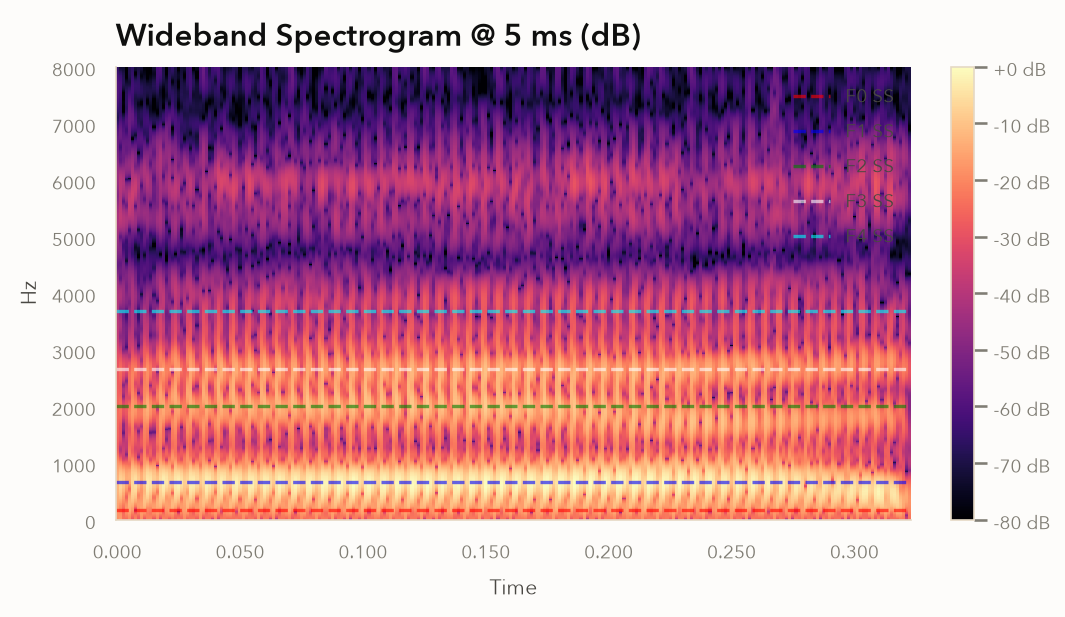

In [195]:
_, ax = plot_spectrogram(audio_, win_dur_wb, sample_rate, title='Wideband Spectrogram @ 5 ms (dB)')

colnames = ['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']
f_ss = zip(['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss'], zip(df.iloc[0][colnames], ['r', 'b', 'g', 'white', 'cyan']))
for colname, (ss, color) in f_ss:
    ax.axhline(y=ss, linestyle='--', color=color, label=colname.upper().replace('_', ' '), alpha=0.6)

plt.legend()
plt.show()

A short, 5 ms window yields excellent time resolution.

Again, with a 5 ms window, we can only distinguish peaks more than 400 Hz apart. That's why the formant bands are blurred vertically; we're detecting density within the region, but unable to granularly isolate the specific frequencies responsible for its power.

This tradeoff is fine for formants; the "central", steady-state values of F1, F2, and F3 are typically separated by at least this much, though we see that F2 and F3 nearly bleed into each other here. That makes sense, as the difference between the lowest value in the F3 region and the highest in F2 is close to the limits of our resolution:

In [196]:
f3_min = min(get_formants(df.iloc[0])[['f3_ss', 'f3_20', 'f3_50', 'f3_80']])
f2_max = max(get_formants(df.iloc[0])[['f2_ss', 'f2_20', 'f2_50', 'f2_80']])
diff = f3_min - f2_max

bin_diff = diff / 200
print(diff, bin_diff)

647.0 3.235


...So there's about a 647 Hz difference between the boundaries of the two regions, corresponding to about 3.2 200 Hz frequency bins of difference.

In [197]:
f_vals_again = get_formants(df.iloc[0])
f_vals_again['f2_ss'] - f_vals_again['f1_ss']

np.float64(1349.0)

Similarly, the bottom of F4 and the top of F3 bleed; again, this matches what we'd expect based on our frequency resolution.

In [198]:
f_vals_again = get_formants(df.iloc[0])
f_vals_again['f4_ss'] - f_vals_again['f3_ss']

np.float64(1032.0)

Regardless, the steady-state formant overlays show that the center of each band does indeed correspond to formant frequency; we can even see a potential F5 that the data omit.

Next, we plot the narrowband spectrum, with a 30 ms window.

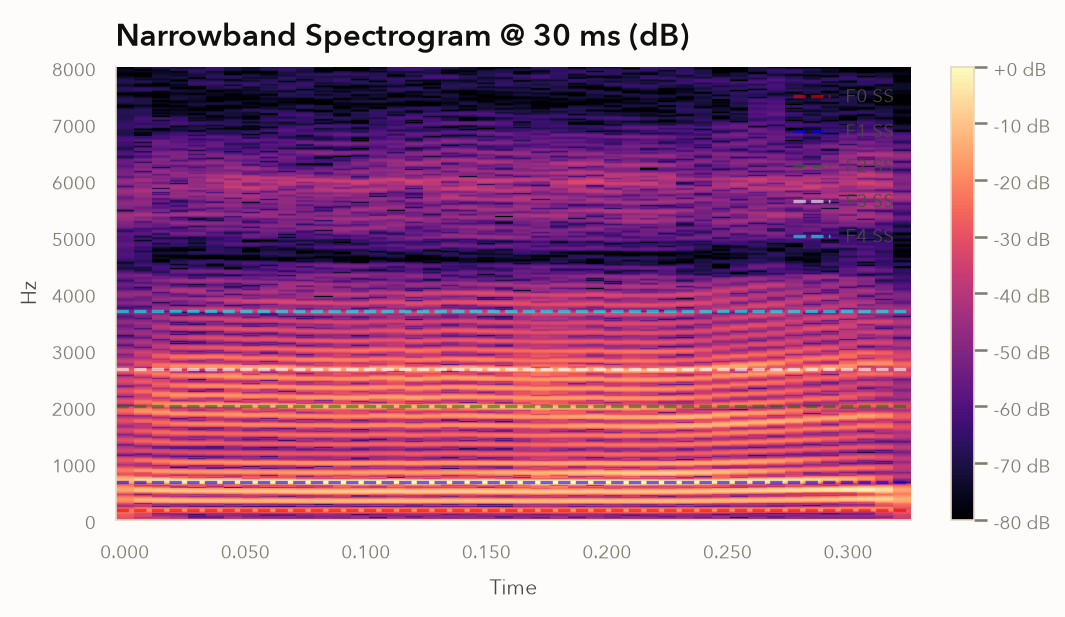

In [199]:
_, ax = plot_spectrogram(audio_, win_dur_nb, sample_rate, title='Narrowband Spectrogram @ 30 ms (dB)')

colnames = ['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']
f_ss = zip(['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss'], zip(df.iloc[0][colnames], ['r', 'b', 'g', 'white', 'cyan']))
for colname, (ss, color) in f_ss:
    ax.axhline(y=ss, linestyle='--', color=color, label=colname.upper().replace('_', ' '), alpha=0.6)

plt.legend()
plt.show()

We now see distinct horizontal bands, each corresponding to a specific frequency. Notice that the steady-state values all directly overlay one of the underlying horizontal lines.

In particular, we can literally see the band corresponding to F0, the fundamental frequency. The bands above it correspond to its harmonics (F1 happens to coincide with $H_{4}$). Because harmonics of F0 are its integer multiples, we can estimate F0 by counting the number of horizontal bands below 1000 Hz:

In [200]:
# counting the band at 1000 Hz
1000 / 6

166.66666666666666

...Surprisingly close to the actual value.

In [201]:
get_formants(df.iloc[0])['f0_ss']

np.int64(174)

Let's compare F0 across our three speaker categories: men, women, and children, using a narrowband (35 ms) window.

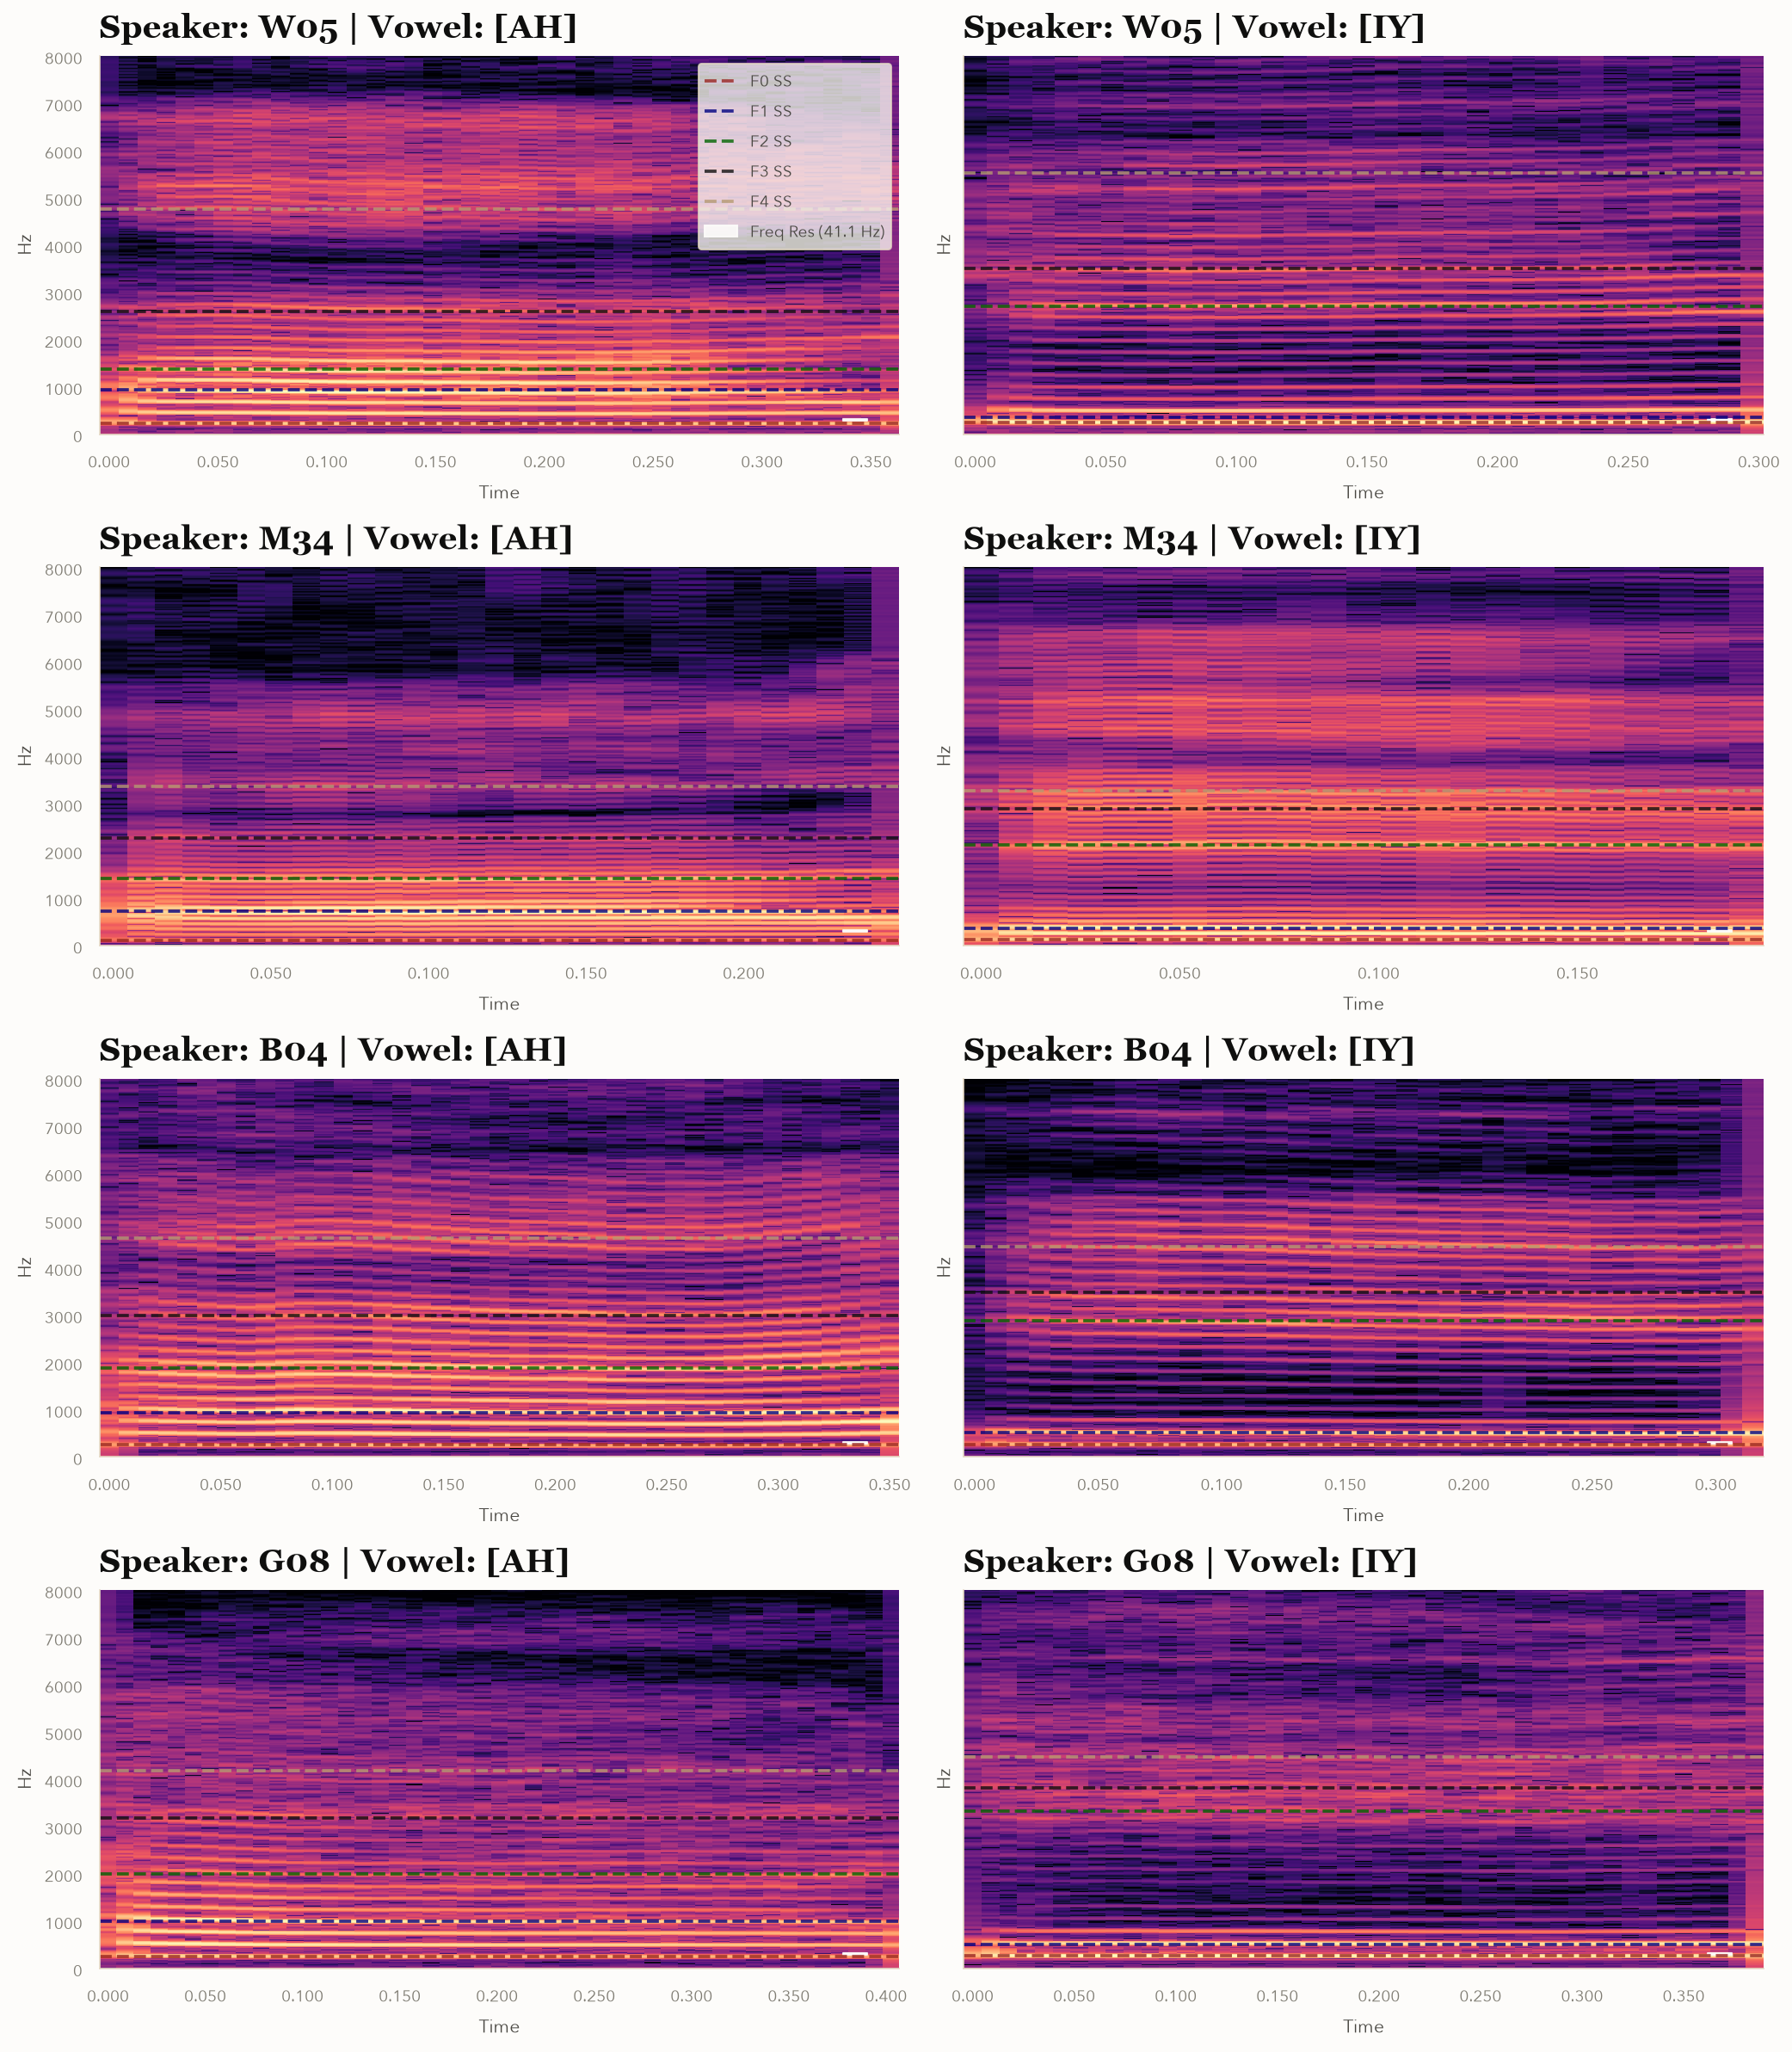

In [202]:
import numpy as np
import matplotlib.pyplot as plt
import librosa as lb
import librosa.display
# Assuming your style file is saved as theme/plotting.py or similar:
from theme.plotting import use, title, TOKENS, CYCLE 

# --- Configurations ---
SAMPLE_RATE = 16000
WIN_DUR_NB = 0.035

# Apply your house style globally (using a slightly larger scale for grid presentation)
use(context="notebook", overrides={"figure.dpi": 150})

# High-contrast line colors selected from your brand TOKENS and CYCLE
# Replaced 'white' and 'cyan' which wash out completely on a parchment background
COLORS = [
    TOKENS["falun-700"],  # Deep Red (F0)
    "navy",               # Dark Blue (F1)
    "darkgreen",          # Deep Green (F2)
    TOKENS["ink-950"],    # Dark Charcoal (F3)
    CYCLE[2]              # Muted Bronze Accent (F4)
]
FN_COLNAMES = ['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']

# --- Hardcoded Vowel Pair ---
VOWEL_PAIR = ['ah', 'iy']  
FIXED_SPEAKERS = {'w': 'w05', 'm': 'm34', 'b': 'b04', 'g': 'g08'}  # speakers discussed in the text below

# --- Dynamic Resolution Calculation ---
win_length = int(WIN_DUR_NB * SAMPLE_RATE)
bin_spacing = SAMPLE_RATE / win_length
freq_res_hz = bin_spacing * 1.44  # -3 dB mainlobe width of the Hann window, in bins

# --- Cross-Speaker Data Selection Logic ---
speaker_groups = [group for _, group in df.groupby(['category', 'speaker_id'])]
valid_speakers = [
    g for g in speaker_groups 
    if set(VOWEL_PAIR).issubset(set(g['vowel'].unique()))
]

selected_rows = []
for target_cat in ['w', 'm', 'b', 'g']:
    cat_pool = [g for g in valid_speakers if g['category'].iloc[0] == target_cat]
    if len(cat_pool) == 0:
        raise ValueError(f"No speaker in category '{target_cat}' has recorded both {VOWEL_PAIR}.")
        
    chosen_speaker_df = next(g for g in cat_pool if g['speaker_id'].iloc[0] == FIXED_SPEAKERS[target_cat])
    for v in VOWEL_PAIR:
        vowel_row = chosen_speaker_df[chosen_speaker_df['vowel'] == v].iloc[0]
        selected_rows.append(vowel_row.to_dict())

# --- Plotting Loop (4 rows x 2 columns = 8 subplots) ---
# --- Plotting Loop (4 rows x 2 columns = 8 subplots) ---
fig, axes = plt.subplots(4, 2, figsize=(14, 16), sharex=False, sharey=True)
axes = axes.flatten()

for idx, row in enumerate(selected_rows):
    ax = axes[idx]
    
    # Load full audio file
    audio_path = row['path'] + '.wav' 
    audio_full, _ = lb.load(audio_path, sr=SAMPLE_RATE)
    
    # --- CROSS-REFERENCING TIMEDATA ---
    time_match = df_timedata.loc[df_timedata['filename'] == row['filename']]
    if not time_match.empty:
        start_ms = time_match.iloc[0]['start']
        end_ms = time_match.iloc[0]['end']
        
        start_sample = int(start_ms * SAMPLE_RATE / 1000)
        end_sample = int(end_ms * SAMPLE_RATE / 1000)
        audio = audio_full[start_sample:end_sample]
    else:
        audio = audio_full
    
    # Compute STFT
    D = lb.stft(audio, win_length=win_length)
    S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)
    
    # Render spectrogram
    img = lb.display.specshow(
        S_db,
        sr=SAMPLE_RATE,
        hop_length=win_length // 4,
        x_axis='time',
        y_axis='hz',
        ax=ax,
    )
    
    # Overlay steady-state formants/pitch lines
    for col, color in zip(FN_COLNAMES, COLORS):
        freq_val = row[col]
        if not np.isnan(freq_val):
            ax.axhline(
                y=freq_val, 
                linestyle='--', 
                color=color, 
                alpha=0.8, 
                linewidth=1.8,
                label=col.upper().replace('_', ' ')
            )
            
    # --- DYNAMIC FREQUENCY RESOLUTION INDICATOR (BOTTOM RIGHT) ---
    x_limits = ax.get_xlim()
    span = x_limits[1] - x_limits[0]
    bar_x_start = x_limits[0] + (span * 0.93)
    bar_x_end = x_limits[0] + (span * 0.96)
    
    center_freq = 300.0  # Safe corner placement
    ax.fill_between(
        x=[bar_x_start, bar_x_end],
        y1=center_freq - (freq_res_hz / 2),
        y2=center_freq + (freq_res_hz / 2),
        color=TOKENS["parchment-50"],   
        alpha=0.9,
        label=f'Freq Res ({freq_res_hz:.1f} Hz)' if idx == 0 else ""
    )
    
    # Apply book serif typography heading format using custom title helper
    title(ax, f"Speaker: {row['speaker_id'].upper()} | Vowel: [{row['vowel'].upper()}]")
    
    # Render high-contrast legend box on the first subplot
    if idx == 0:
        ax.legend(loc='upper right', frameon=True, facecolor=TOKENS["parchment-100"], edgecolor=TOKENS["parchment-300"])

plt.tight_layout()
plt.show()

Same thing, but wideband (2.5 ms window)...

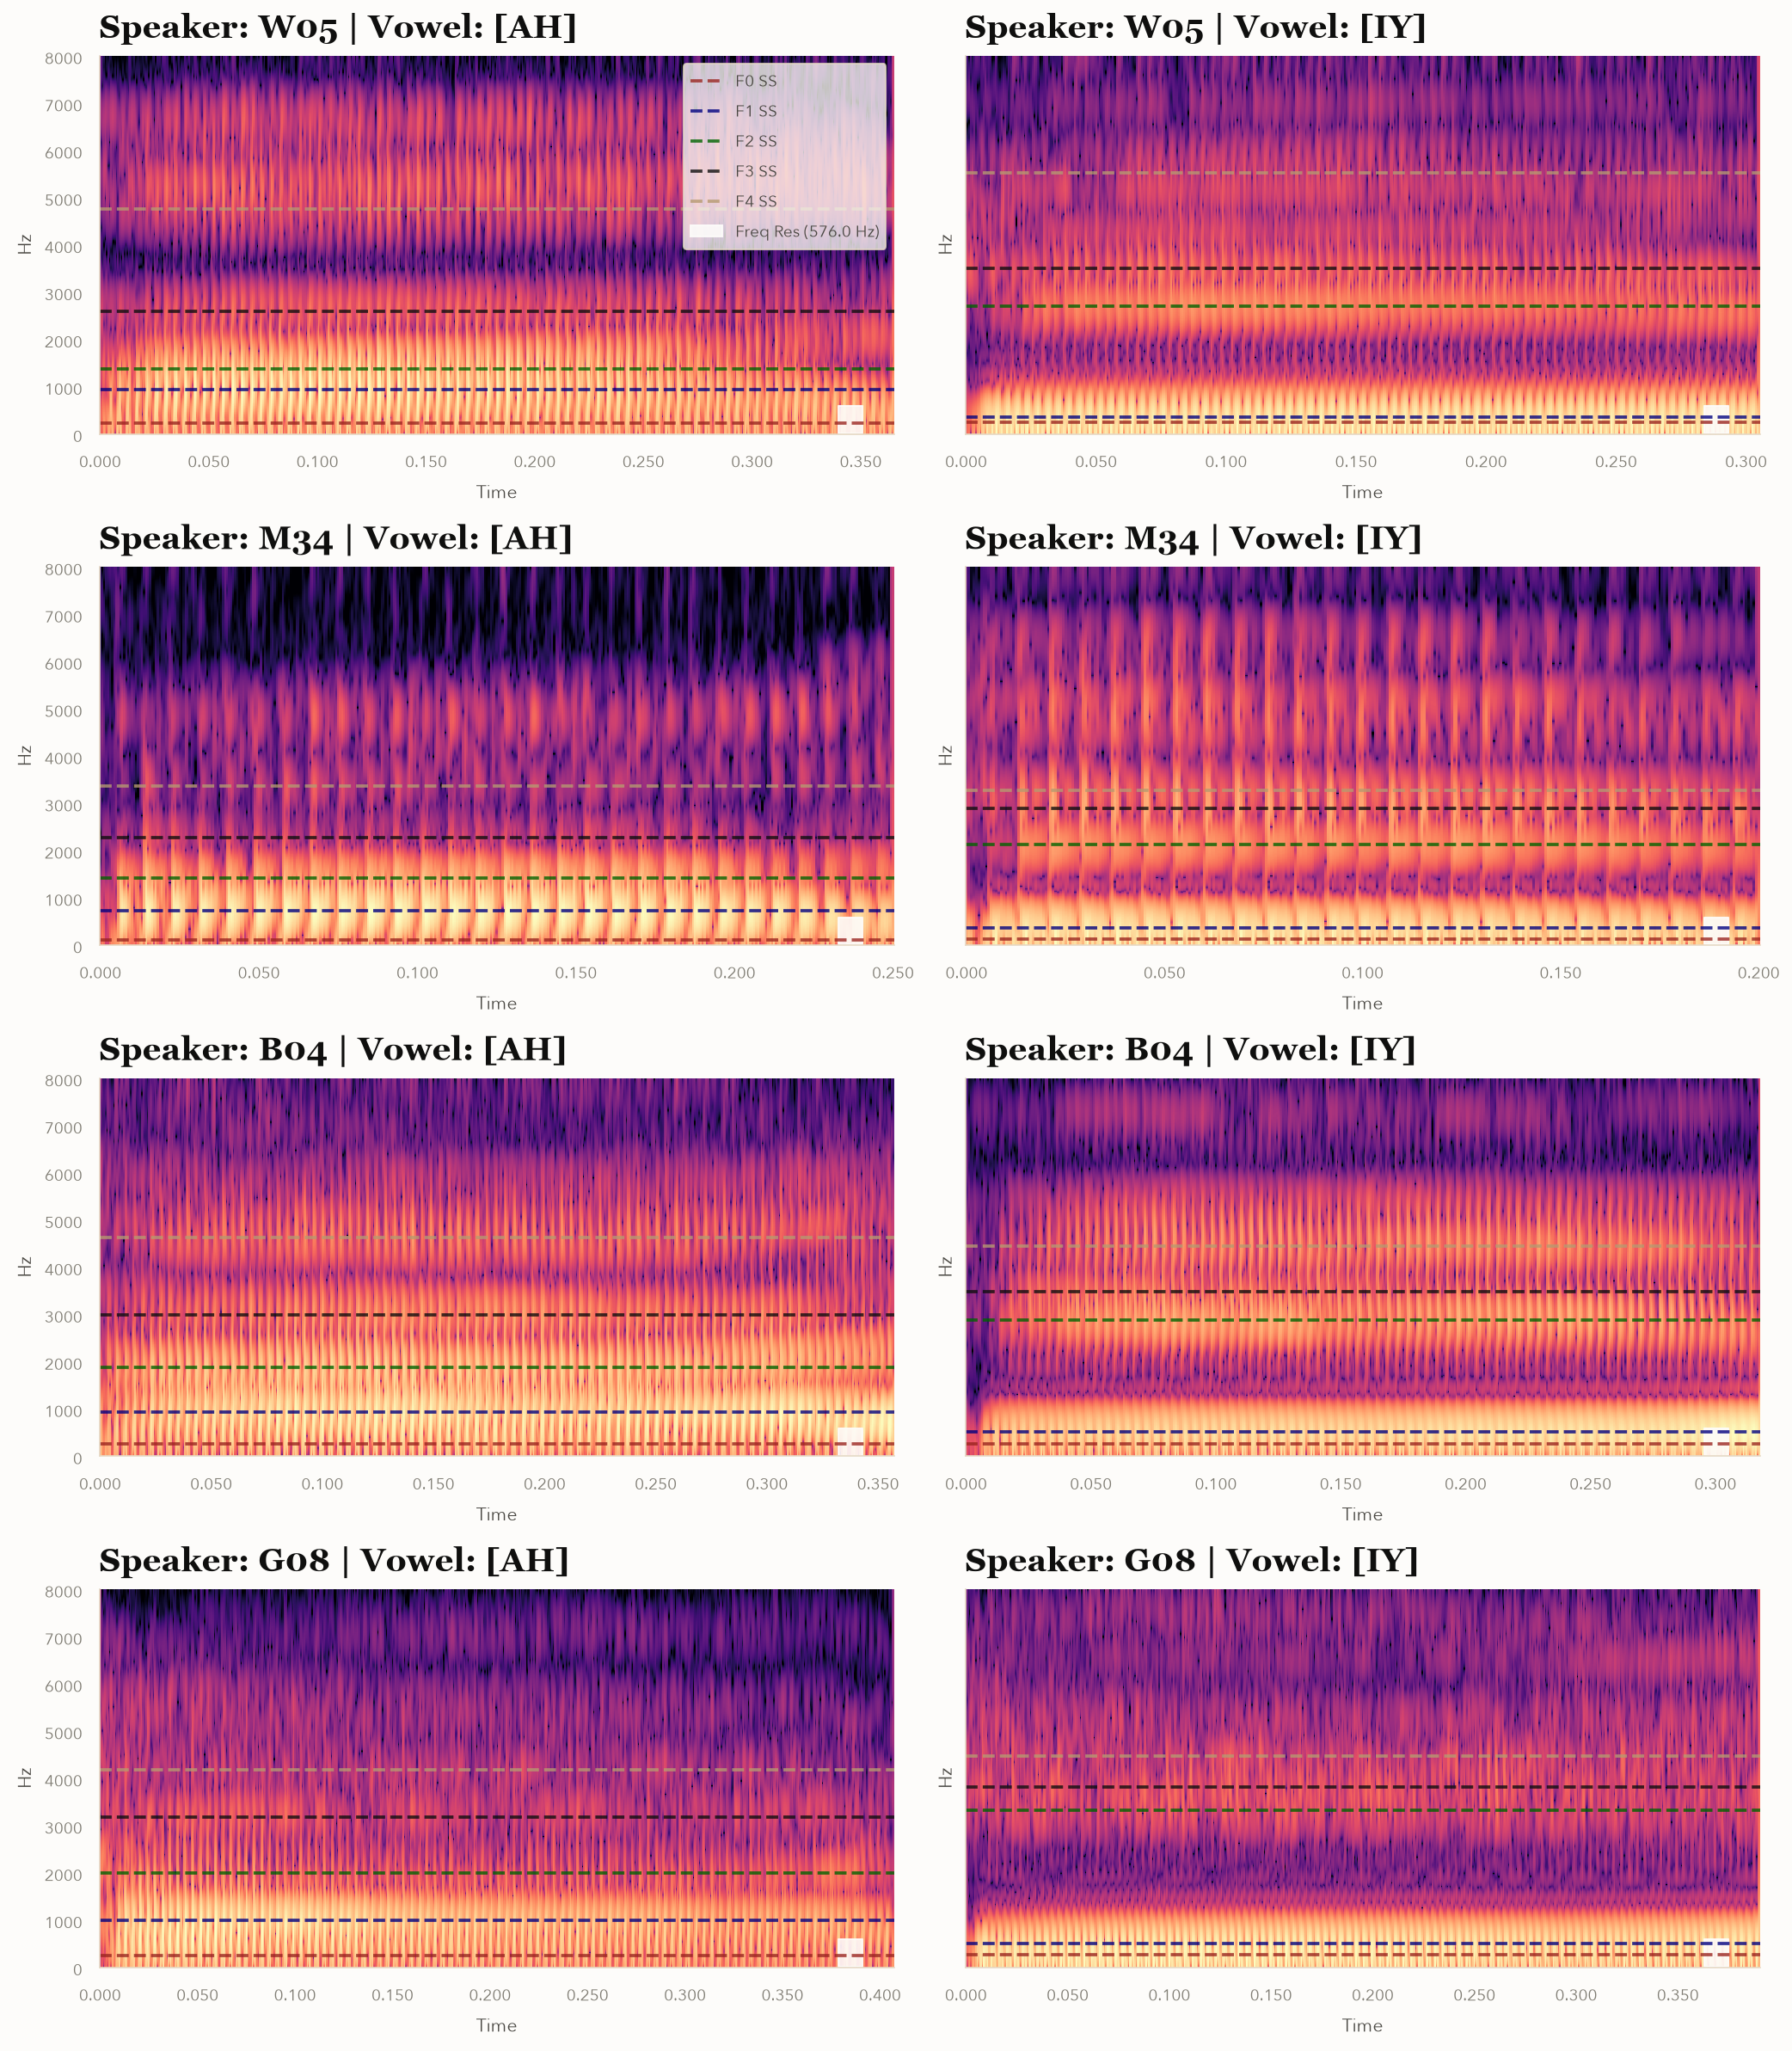

In [203]:
import numpy as np
import matplotlib.pyplot as plt
import librosa as lb
import librosa.display
# Assuming your style file is saved as theme/plotting.py or similar:
from theme.plotting import use, title, TOKENS, CYCLE 

# --- Configurations ---
SAMPLE_RATE = 16000
WIN_DUR_WB = 0.0025

# Apply your house style globally (using a slightly larger scale for grid presentation)
use(context="notebook", overrides={"figure.dpi": 150})

# High-contrast line colors selected from your brand TOKENS and CYCLE
# Replaced 'white' and 'cyan' which wash out completely on a parchment background
COLORS = [
    TOKENS["falun-700"],  # Deep Red (F0)
    "navy",               # Dark Blue (F1)
    "darkgreen",          # Deep Green (F2)
    TOKENS["ink-950"],    # Dark Charcoal (F3)
    CYCLE[2]              # Muted Bronze Accent (F4)
]
FN_COLNAMES = ['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']

# --- Hardcoded Vowel Pair ---
VOWEL_PAIR = ['ah', 'iy']  
FIXED_SPEAKERS = {'w': 'w05', 'm': 'm34', 'b': 'b04', 'g': 'g08'}  # speakers discussed in the text below

# --- Dynamic Resolution Calculation ---
win_length = int(WIN_DUR_WB * SAMPLE_RATE)
bin_spacing = SAMPLE_RATE / win_length
freq_res_hz = bin_spacing * 1.44  # -3 dB mainlobe width of the Hann window, in bins

# --- Cross-Speaker Data Selection Logic ---
speaker_groups = [group for _, group in df.groupby(['category', 'speaker_id'])]
valid_speakers = [
    g for g in speaker_groups 
    if set(VOWEL_PAIR).issubset(set(g['vowel'].unique()))
]

selected_rows = []
for target_cat in ['w', 'm', 'b', 'g']:
    cat_pool = [g for g in valid_speakers if g['category'].iloc[0] == target_cat]
    if len(cat_pool) == 0:
        raise ValueError(f"No speaker in category '{target_cat}' has recorded both {VOWEL_PAIR}.")
        
    chosen_speaker_df = next(g for g in cat_pool if g['speaker_id'].iloc[0] == FIXED_SPEAKERS[target_cat])
    for v in VOWEL_PAIR:
        vowel_row = chosen_speaker_df[chosen_speaker_df['vowel'] == v].iloc[0]
        selected_rows.append(vowel_row.to_dict())

# --- Plotting Loop (4 rows x 2 columns = 8 subplots) ---
# --- Plotting Loop (4 rows x 2 columns = 8 subplots) ---
fig, axes = plt.subplots(4, 2, figsize=(14, 16), sharex=False, sharey=True)
axes = axes.flatten()

for idx, row in enumerate(selected_rows):
    ax = axes[idx]
    
    # Load full audio file
    audio_path = row['path'] + '.wav' 
    audio_full, _ = lb.load(audio_path, sr=SAMPLE_RATE)
    
    # --- CROSS-REFERENCING TIMEDATA ---
    time_match = df_timedata.loc[df_timedata['filename'] == row['filename']]
    if not time_match.empty:
        start_ms = time_match.iloc[0]['start']
        end_ms = time_match.iloc[0]['end']
        
        start_sample = int(start_ms * SAMPLE_RATE / 1000)
        end_sample = int(end_ms * SAMPLE_RATE / 1000)
        audio = audio_full[start_sample:end_sample]
    else:
        audio = audio_full
    
    # Compute STFT
    D = lb.stft(audio, win_length=win_length)
    S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)
    
    # Render spectrogram
    img = lb.display.specshow(
        S_db,
        sr=SAMPLE_RATE,
        hop_length=win_length // 4,
        x_axis='time',
        y_axis='hz',
        ax=ax,
    )
    
    # Overlay steady-state formants/pitch lines
    for col, color in zip(FN_COLNAMES, COLORS):
        freq_val = row[col]
        if not np.isnan(freq_val):
            ax.axhline(
                y=freq_val, 
                linestyle='--', 
                color=color, 
                alpha=0.8, 
                linewidth=1.8,
                label=col.upper().replace('_', ' ')
            )
            
    # --- DYNAMIC FREQUENCY RESOLUTION INDICATOR (BOTTOM RIGHT) ---
    x_limits = ax.get_xlim()
    span = x_limits[1] - x_limits[0]
    bar_x_start = x_limits[0] + (span * 0.93)
    bar_x_end = x_limits[0] + (span * 0.96)
    
    center_freq = 300.0  # Safe corner placement
    ax.fill_between(
        x=[bar_x_start, bar_x_end],
        y1=center_freq - (freq_res_hz / 2),
        y2=center_freq + (freq_res_hz / 2),
        color=TOKENS["parchment-50"],   
        alpha=0.9,
        label=f'Freq Res ({freq_res_hz:.1f} Hz)' if idx == 0 else ""
    )
    
    # Apply book serif typography heading format using custom title helper
    title(ax, f"Speaker: {row['speaker_id'].upper()} | Vowel: [{row['vowel'].upper()}]")
    
    # Render high-contrast legend box on the first subplot
    if idx == 0:
        ax.legend(loc='upper right', frameon=True, facecolor=TOKENS["parchment-100"], edgecolor=TOKENS["parchment-300"])

plt.tight_layout()
plt.show()

In both plots compare the spectrograms corresponding to the same two vowels uttered by four different speakers, representing each of our categories. The vowels were "ah", IPA /ɑ/, the [open/low back unrounded vowel](https://en.wikipedia.org/wiki/File:Open_back_unrounded_vowel.ogg); and "iy", IPA /i/, the [close/high front unrounded vowel](https://en.wikipedia.org/wiki/File:Close_front_unrounded_vowel.ogg).

In /ɑ/:

- We have F1 fairly close to F2. Eyeballing, Speaker W05's F1 and F2 are within 500 Hz of one another, ~1000 Hz (`vowdata`: 935) and ~1200 Hz (`vowdata`: 1377). The spread is wider for M34, appearing closer to ~900 Hz (`vowdata`: 722) and ~1200 Hz (`vowdata`: 1411). These are in the ballpark of the average values of 730 and 850 Hz reported by PB for men and women, respectively [2], as well as Ladefoged and Johnson more recently [3].
- B04 and G08, both children, show a striking separation of nearly ~1000 Hz between F1 and F2 (`vowdata`: B04 942, G08 1007). It's well-known that children's voices feature a higher fundamental frequency than those of adults, often in the range of 250-600 Hz [4]. Harmonics of the F0 occur at its integer multiples. A child whose F0 is 300 Hz, then, generates harmonics at 600, 900, 1200 Hz, etc. At the other extreme, an adult male whose F0 is 100 Hz generates harmonics at 200, 300, 400 Hz, etc. Lower F0 means a higher density of harmonics in a given range of frequencies; this, in turn, provides more "source" for the vocal tract to amplify into formants. In other words, lower F0 generates enough harmonics to adequately sample the behavior of the vocal filter—i.e., characterize the vocal tract transfer function—whereas the widely spaced harmonics of children often fail to do so [4].
- This has major implications for speech recognition systems, but for our purposes, simply note that this aligns with expectations.

In /i/:

- F1 and F2 are widely separated. Speaker W05 has F1 near what looks like ~250 Hz (`vowdata`: 346), with F2 around ~2800 Hz (`vowdata`: 2703); M34 exhibits a comparable gap of ~250 Hz (`vowdata`: 365) and ~2200 Hz (`vowdata`: 2119), again in the ballpark of the PB data, which report F1 at 310 Hz and F2 of 2790 Hz, and F1 at 270 vs F2 at 2290 Hz, respectively.
- Despite variance in F0, the distribution of formants looks similar in children, with F1 and F2 widely separated. PB report F1 at 370 Hz and F2 near 3200 Hz for children, which seems to agree with G08's and B04's /i/-vowel data (`vowdata`: G08 507 / 3319, B04 509 / 2873).

M34's F0 is systematically lower than that of the other speakers; B04 and G08 have roughly coincident F0; and W05's F0 is a little closer the vicinity of B04 and G08 due to a higher F0 (`vowdata` F0, /ɑ/ / /i/: M34 115 / 130, W05 226 / 249, B04 250 / 260, G08 249 / 263).

### Formant Space & Normalization

Clearly, there are observable differences between speakers—e.g., F0—but certain properties of interest remain somewhat invariant, such as the relative placement of formant frequencies in wideband.

Let's group by category and take summary statistics.

In [204]:
groups = df[['category'] + acoustic_cols].groupby('category')

In [205]:
groups.mean()

,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
category,,,,,,,,,,,,,,,
b,281.891975,236.074074,638.037037,1914.984227,3027.788462,4283.762411,640.348765,1919.214511,3025.745223,643.240741,1924.712934,3009.367412,626.975309,2003.919003,3035.326984
g,293.333333,238.350877,667.692982,2011.000000,3199.206278,4341.640212,670.105263,2008.669604,3210.269058,672.815789,2017.471366,3175.009009,647.052632,2104.250000,3187.660714
m,238.318519,131.218519,523.575926,1508.120370,2517.204887,3540.719731,526.140741,1510.188889,2515.492481,522.466667,1514.636364,2515.510397,505.635185,1580.935185,2522.039548
w,297.307292,220.401042,616.925347,1763.167247,2866.021429,4165.618110,623.611111,1768.372822,2865.489286,621.526042,1771.863636,2860.103943,599.750000,1856.585069,2870.921005


In [206]:
groups.std()

,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
category,,,,,,,,,,,,,,,
b,58.915409,28.300916,156.153726,626.671347,403.954822,416.522064,155.747092,619.273291,394.890868,160.769427,613.014317,400.636396,156.041669,550.585767,401.577952
g,62.912031,20.931810,186.776605,638.041077,418.818332,358.657941,185.119148,632.273571,417.320150,191.857650,619.241852,419.330170,175.554770,557.032646,424.778382
m,52.959172,22.034137,121.769117,488.362307,313.870692,278.366850,118.824556,482.399466,314.601811,126.351575,480.812356,309.153886,120.226866,421.405676,297.638448
w,63.231619,23.220694,161.664880,606.156512,355.884717,365.200310,159.493388,600.351145,354.189134,165.278156,577.449976,351.074217,159.786814,523.877583,334.563096


Immediately, F0 splits into two categories: `b`, `g`, and `w`; and `m`. As mentioned above, this has implications for signal processing and characterizing the vocal transfer function; special care must be taken analyzing and modeling speech from these populations (models typically underperform for these demographics) (_citation needed_).

Pitch and harmonic structure vary, but the relative distribution of formants remains similar across categories.

Plotting the values of F1 vs F2 and color-coding by vowel, we see clusters corresponding to vowel type.

In [207]:
count = 20
state = 42

In [208]:
df_f1_f2 = df[['f1_ss', 'f2_ss', 'category', 'vowel', 'speaker_id']].rename(columns={'f1_ss': 'f1', 'f2_ss': 'f2'})

In [209]:
def plot_f1_f2(df_f1_f2, category: str = 'w'):
    filtered_df = df_f1_f2[df_f1_f2['category'] == category]
    
    ax = sns.jointplot(
        data=filtered_df,
        x='f2',
        y='f1',
        hue='vowel',
        # levels=1,
    )
    
    ax.ax_joint.invert_xaxis()
    ax.ax_joint.invert_yaxis()
    
    # Gemini-provided styling
    # 2. Define the corner vowels mapping to their clean display characters
    corner_vowels = {"iy": "i", "uw": "u", "ah": "a"}
    
    # 3. Calculate centroids and add text labels to the joint plot
    for vowel, display_label in corner_vowels.items():
        # Slice the dataframe down to just the tokens for this specific vowel
        vowel_cluster = filtered_df[filtered_df['vowel'] == vowel]
    
        # Calculate the mean (centroid) coordinates for the cluster
        center_x = vowel_cluster['f2'].mean()
        center_y = vowel_cluster['f1'].mean()
    
        # Draw the label directly over the center of the vowel cluster
        ax.ax_joint.text(
            x=center_x,
            y=center_y,
            s=display_label,
            fontdict=dict(
                size=12, weight='bold', color='black'
            ),  # Larger, bold text for clarity
            horizontalalignment='center',
            verticalalignment='center',
            bbox=dict(
                facecolor='white', alpha=0.8, edgecolor='black', boxstyle='circle,pad=0.3'
            ),  # A crisp circular boundary around the vowel symbol
        )
    
    plt.title('F1 vs F2: Recovering the IPA Vowel Space')
    plt.tight_layout()
    plt.show()

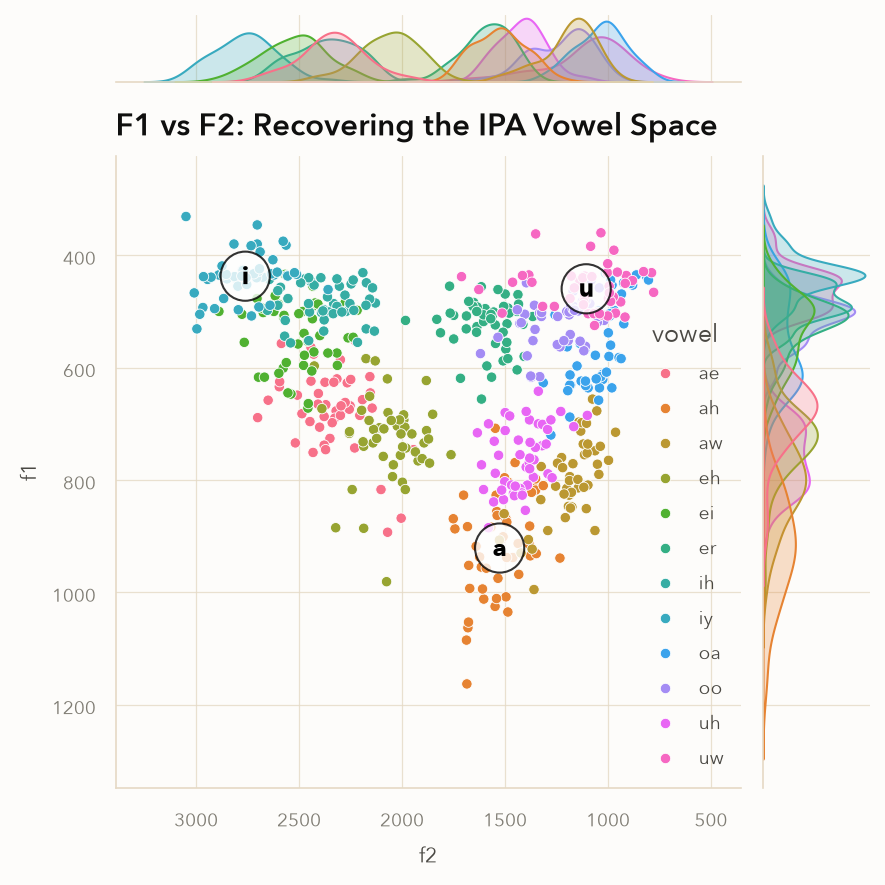

In [210]:
plot_f1_f2(df_f1_f2, 'w')

This famously reproduces the corners of the [IPA vowel chart](https://upload.wikimedia.org/wikipedia/commons/5/5a/Vowel_quadrilateral_%28IPA_1949%29.svg)

Inspecting `m` or `g` doesn't change the relative position.

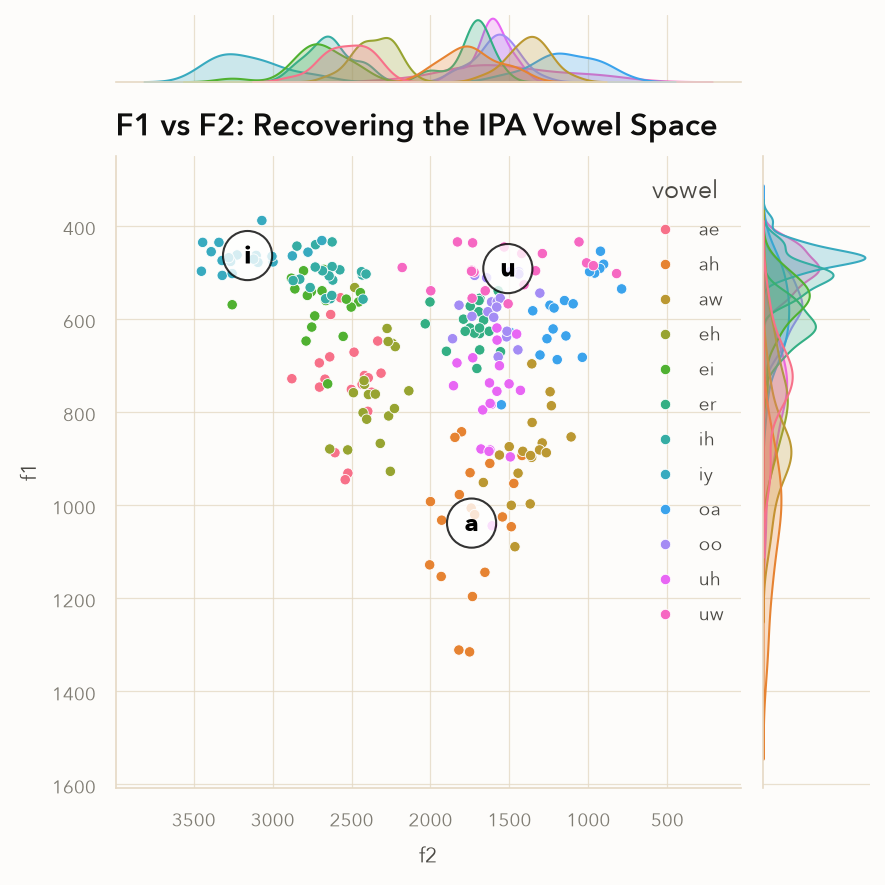

In [211]:
plot_f1_f2(df_f1_f2, 'g')

Distinguishing formants, then, indeed seems to have more to do with their relative placement. Specifically:

- Low first formant and high second formant is associated with close/high unrounded vowels.
- F1 is inversely related to **height**. F2 is related to **backness**/**advancement**.

F1 and F2 are generally taken as sufficient for the human ear to identify most vowels[2] [3].

### Information in Vowels

Following Ladefoged and Broadbent's [_Information Conveyed by Vowels_](https://linguistics.berkeley.edu/~kjohnson/readings/Ladefoged_Broadbent_1957%20copy.pdf), vowels are often taken to convey three categories of information [5] [6]:

- **Linguistic information**, which communicates lexical information to the listener;
- **Socio-linguistic information**, which carries information about the speaker's background;
- **Personal information** (sometimes _anatomical/physiological information_), which serves to identify the speaker.

Their results lend credence to an earlier hypothesis due to Joos that the information contained in a vowel depends jointly on the relationship between formant frequencies for that vowel, and the formant frequencies of other vowels pronounced by that speaker [5].

In other words, linguistic information content is a function of the formant frequencies realized by the speaker for a given vowel, in the context of the the realization of their broader vowel space.

LB consider it plausible that socio-linguistic information is also largely independent of absolute formant frequency, determined instead by relative relationship [5].

Finally, they posit that absolute formant frequency may influence personal information content, in part because they're a function of the speaker's physical characteristics [5]. As such, it's plausible to expect that listeners perceptually normalize these differences away, in line with the suggestion that the bulk of linguistic and socio-linguistic information is accounted for by the relative distribution of a speaker's formant space.

These differences are clearly meaningful, however: for one, they distinguish categories in this dataset.

In some circumstances, however, this variation may be undesirable. In our case—classifying vowels, under the assumption there is some reliable, speaker-independent representation of each one, eliminating differences due to variance in factors like vocal tract length is likely to improve performance of our model.

Taking after Adank et al.'s famous evaluation of various methods, vowel normalization has the following general goals [8]:

- **Preserve Phonemic Information**, or retain information about the relationships between the speaker's phonemes;
- **Preserve Sociolinguistic Information**, or retain information about the speaker's background, such as accent, vowel realization, etc.; and
- **Minimize Anatomical/Physiological Variation**, or eliminate information that varies exclusively due to factors such as head size, like pitch, and do not materially influence the semantics of the underlying utterance.

Note that these correspond directly to LB's three types of information, and specifically, to preserving the features responsible for distinguishing sociolinguistic and linguistic information preferentially, while eliminating factors due purely to individual variance.

Normalization can be **extrinsic** or **intrinsic**, and be performed with respect to any of the below [6]:

- **Vowel**: Intrinsic vowel normalization formants in a vowel using _only_ the formant data in that vowel. Extrinsic normalization uses formant frequencies from _each_ vowel of a speaker's vowel space.
- **Formant**: As above, but intrinsic normalization uses a _single_ formant, whereas extrinsic uses _multiple_ formants.
- **Speaker**: Intrinsic when only a speaker's own data is used to normalize data; extrinsic when aggregate data is used instead.

If LB's observations are true, it suggests that normalizing data in a way that retains the shape of the speaker's vowel space, but eliminates the influence of factors such as vocal tract length, should preserve sufficient structure to predict the identity of test inputs.

This represents **speaker-intrinsic**, **vowel-extrinsic** normalization: We need to normalize formant frequencies per-speaker (speaker intrinsic), but relative to each speaker's entire vowel space (vowel extrinsic). Geometrically, such a transformation should scale and translate the space, but otherwise leave its "center of gravity" relatively unchanged.

Adank is one of the original sources of the oft-cited claim that Lobanov normalization is one of the best-performing methods across metrics for most purposes [6] [8]. Under certain circumstances, it too is susceptible to erasing sociolinguistic information from datasets [9], but it's plausible to expect minimal effect due to speakers being drawn from the same Sprachraum.

For other methods, see [Dr Barlaz's coverage of methods in R](https://marissabarlaz.github.io/portfolio/vowelnormalization/), or the [R documentation directly](https://cran.r-project.org/web/packages/tidynorm/vignettes/norm-methods.html#lobanov-lobanov).

First, we implement a method to perform Lobanov normalization...

In [212]:
def lobanov(df_, cols, speaker='speaker_id'):
    # generated (Claude): per-speaker z-score of each column in `cols`, added as `<col>_lbnv`
    grouped = df_.groupby(speaker)[cols]
    z = (df_[cols] - grouped.transform('mean')) / grouped.transform('std')
    out = df_.drop(columns=[f'{c}_lbnv' for c in cols], errors='ignore')  # safe to re-run
    return out.join(z.add_suffix('_lbnv'))

...And plot it.

In [213]:
def plot_f1_f2_lobanov(df_f1_f2, category: str = "w"):
    filtered_df = df_f1_f2[df_f1_f2["category"] == category]

    # 1. Update the x and y parameters to use the _lbnv columns
    ax = sns.jointplot(
        data=filtered_df,
        x="f2_lbnv",
        y="f1_lbnv",
        hue="vowel",
    )

    # Invert the normalized axes (standard for phonetics vowel spaces)
    ax.ax_joint.invert_xaxis()
    ax.ax_joint.invert_yaxis()

    corner_vowels = {"iy": "i", "uw": "u", "ah": "a"}

    # 2. Update centroids calculation to use the _lbnv columns
    for vowel, display_label in corner_vowels.items():
        vowel_cluster = filtered_df[filtered_df["vowel"] == vowel]

        # Use normalized columns for coordinates
        center_x = vowel_cluster["f2_lbnv"].mean()
        center_y = vowel_cluster["f1_lbnv"].mean()

        # Check for NaN in case a corner vowel doesn't exist in this specific category slice
        if not (pd.isna(center_x) or pd.isna(center_y)):
            ax.ax_joint.text(
                x=center_x,
                y=center_y,
                s=display_label,
                fontdict=dict(size=12, weight="bold", color="black"),
                horizontalalignment="center",
                verticalalignment="center",
                bbox=dict(
                    facecolor="white",
                    alpha=0.8,
                    edgecolor="black",
                    boxstyle="circle,pad=0.3",
                ),
            )

    # 3. Correct way to add a title to a Seaborn JointGrid without borking the layout
    ax.figure.suptitle(
        "Normalized F1 vs F2: Recovering the IPA Vowel Space", y=1.02
    )

    plt.show()

In [214]:
# F1-F3 along the trajectory; duration, F0, and F4 are excluded
formant_cols = [f'f{n}_{t}' for n in (1, 2, 3) for t in ('ss', '20', '50', '80')]
df = lobanov(df, formant_cols)
df.filter(like='_lbnv').describe().round(2)

,f1_ss_lbnv,f1_20_lbnv,f1_50_lbnv,f1_80_lbnv,f2_ss_lbnv,f2_20_lbnv,f2_50_lbnv,f2_80_lbnv,f3_ss_lbnv,f3_20_lbnv,f3_50_lbnv,f3_80_lbnv
count,1668.00,1668.00,1668.00,1668.00,1658.00,1658.00,1655.00,1665.00,1627.00,1629.00,1622.00,1627.00
mean,0.00,0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00
std,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.96
min,-1.84,-1.89,-1.78,-1.68,-1.71,-1.76,-1.71,-2.07,-3.10,-3.08,-3.13,-3.13
25%,-0.76,-0.75,-0.74,-0.81,-0.82,-0.85,-0.75,-0.49,-0.35,-0.35,-0.32,-0.33
50%,-0.23,-0.21,-0.32,-0.26,-0.31,-0.33,-0.29,-0.11,0.10,0.09,0.08,0.12
75%,0.72,0.69,0.79,0.82,0.92,0.93,0.76,0.50,0.52,0.53,0.50,0.54
max,2.84,2.86,2.76,2.42,2.05,1.99,2.11,2.11,2.73,2.75,2.71,2.80


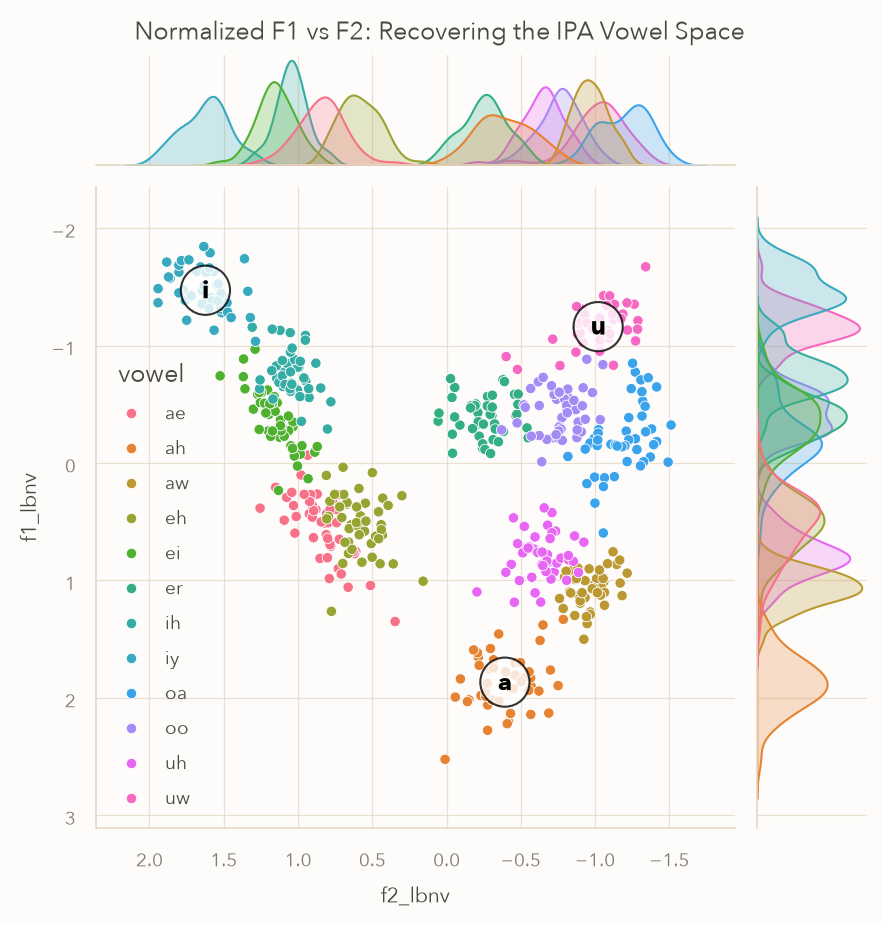

In [215]:
# Lobanov values come from the full df (per-speaker stats), joined on row index
lbnv = df[['f1_ss_lbnv', 'f2_ss_lbnv']].set_axis(['f1_lbnv', 'f2_lbnv'], axis=1)
plot_f1_f2_lobanov(df_f1_f2.join(lbnv), 'm')

This transforms our units to dimensionless quantities while preserving the comparability of different speakers' vowel spaces.

#### Vowel Space: Raw vs. Lobanov

All tokens, by category. Ellipses cover 2 SD of each vowel's F1/F2 distribution; corner vowels /i/, /ɑ/, /u/ in red.

In [216]:
# generated (Claude): vowel-space plotting helpers
from matplotlib.patches import Ellipse

CORNER_VOWELS = {'iy', 'ah', 'uw'}
CATEGORY_NAMES = {'m': 'Men', 'w': 'Women', 'b': 'Boys', 'g': 'Girls'}


def cov_ellipse(x, y, n_std=2.0, **kwargs):
    """Ellipse at the mean of (x, y), axes along the eigenvectors of their covariance."""
    eigvals, eigvecs = np.linalg.eigh(np.cov(x, y))  # ascending eigenvalues
    major = eigvecs[:, 1]
    angle = np.degrees(np.arctan2(major[1], major[0]))
    width, height = 2 * n_std * np.sqrt(eigvals[::-1])
    return Ellipse((x.mean(), y.mean()), width, height, angle=angle, **kwargs)


def plot_vowel_space(data, f1, f2, ax, trajectory=None):
    """F2 on x, F1 on y. `trajectory`: ordered (f1, f2) column pairs; draws each vowel's mean path."""
    pts = data[[f1, f2, 'vowel']].dropna()
    ax.scatter(pts[f2], pts[f1], s=5, color=PALETTE['muted'], alpha=0.2, linewidths=0)
    for vowel, g in pts.groupby('vowel'):
        color = PALETTE['accent'] if vowel in CORNER_VOWELS else TOKENS['ink-800']
        ax.add_patch(cov_ellipse(g[f2], g[f1], fill=False, edgecolor=color,
                                 linewidth=1.2, alpha=0.35 if trajectory else 0.9))
        if trajectory:
            path = data.loc[data['vowel'] == vowel, [c for pair in trajectory for c in pair]].mean()
            xs = [path[c2] for _, c2 in trajectory]
            ys = [path[c1] for c1, _ in trajectory]
            ax.plot(xs[:-1], ys[:-1], color=color, linewidth=1.5)
            ax.annotate('', xy=(xs[-1], ys[-1]), xytext=(xs[-2], ys[-2]),
                        arrowprops=dict(arrowstyle='->', color=color, linewidth=1.5))
        ax.text(g[f2].mean(), g[f1].mean(), vowels_map[vowel], ha='center', va='center',
                fontsize=11, color=PALETTE['heading'],
                fontfamily='DejaVu Sans',  # house fonts lack IPA glyphs (ɪ ɛ ɑ ɔ ʊ ʌ ɝ)
                bbox=dict(boxstyle='round,pad=0.15', facecolor=PALETTE['background'],
                          edgecolor='none', alpha=0.75))


def plot_vowel_grid(data, trajectory=False):
    """Row 1: raw Hz; row 2: Lobanov z-scores. One column per speaker category; axes shared per row."""
    rows = [
        ('Hz', '', 'Hz'),
        ('Lobanov z', '_lbnv', 'z'),
    ]
    times = ['20', '50', '80']
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.5), sharex='row', sharey='row')
    for r, (label, suffix, unit) in enumerate(rows):
        traj = [(f'f1_{t}{suffix}', f'f2_{t}{suffix}') for t in times] if trajectory else None
        for c, cat in enumerate(['m', 'w', 'b', 'g']):
            ax = axes[r, c]
            plot_vowel_space(data[data['category'] == cat], f'f1_ss{suffix}', f'f2_ss{suffix}', ax, traj)
            title(ax, f"{CATEGORY_NAMES[cat]} ({label})")
            ax.set_xlabel(f'F2 ({unit})')
            ax.set_ylabel(f'F1 ({unit})' if c == 0 else '')
        axes[r, 0].invert_xaxis()  # shared within the row
        axes[r, 0].invert_yaxis()
    suffix_note = ', with mean trajectories (20% to 50% to 80%, arrow at 80%)' if trajectory else ''
    fig.suptitle(f'Steady-state F1 vs F2, all tokens{suffix_note}', y=1.01)
    plt.tight_layout()
    plt.show()

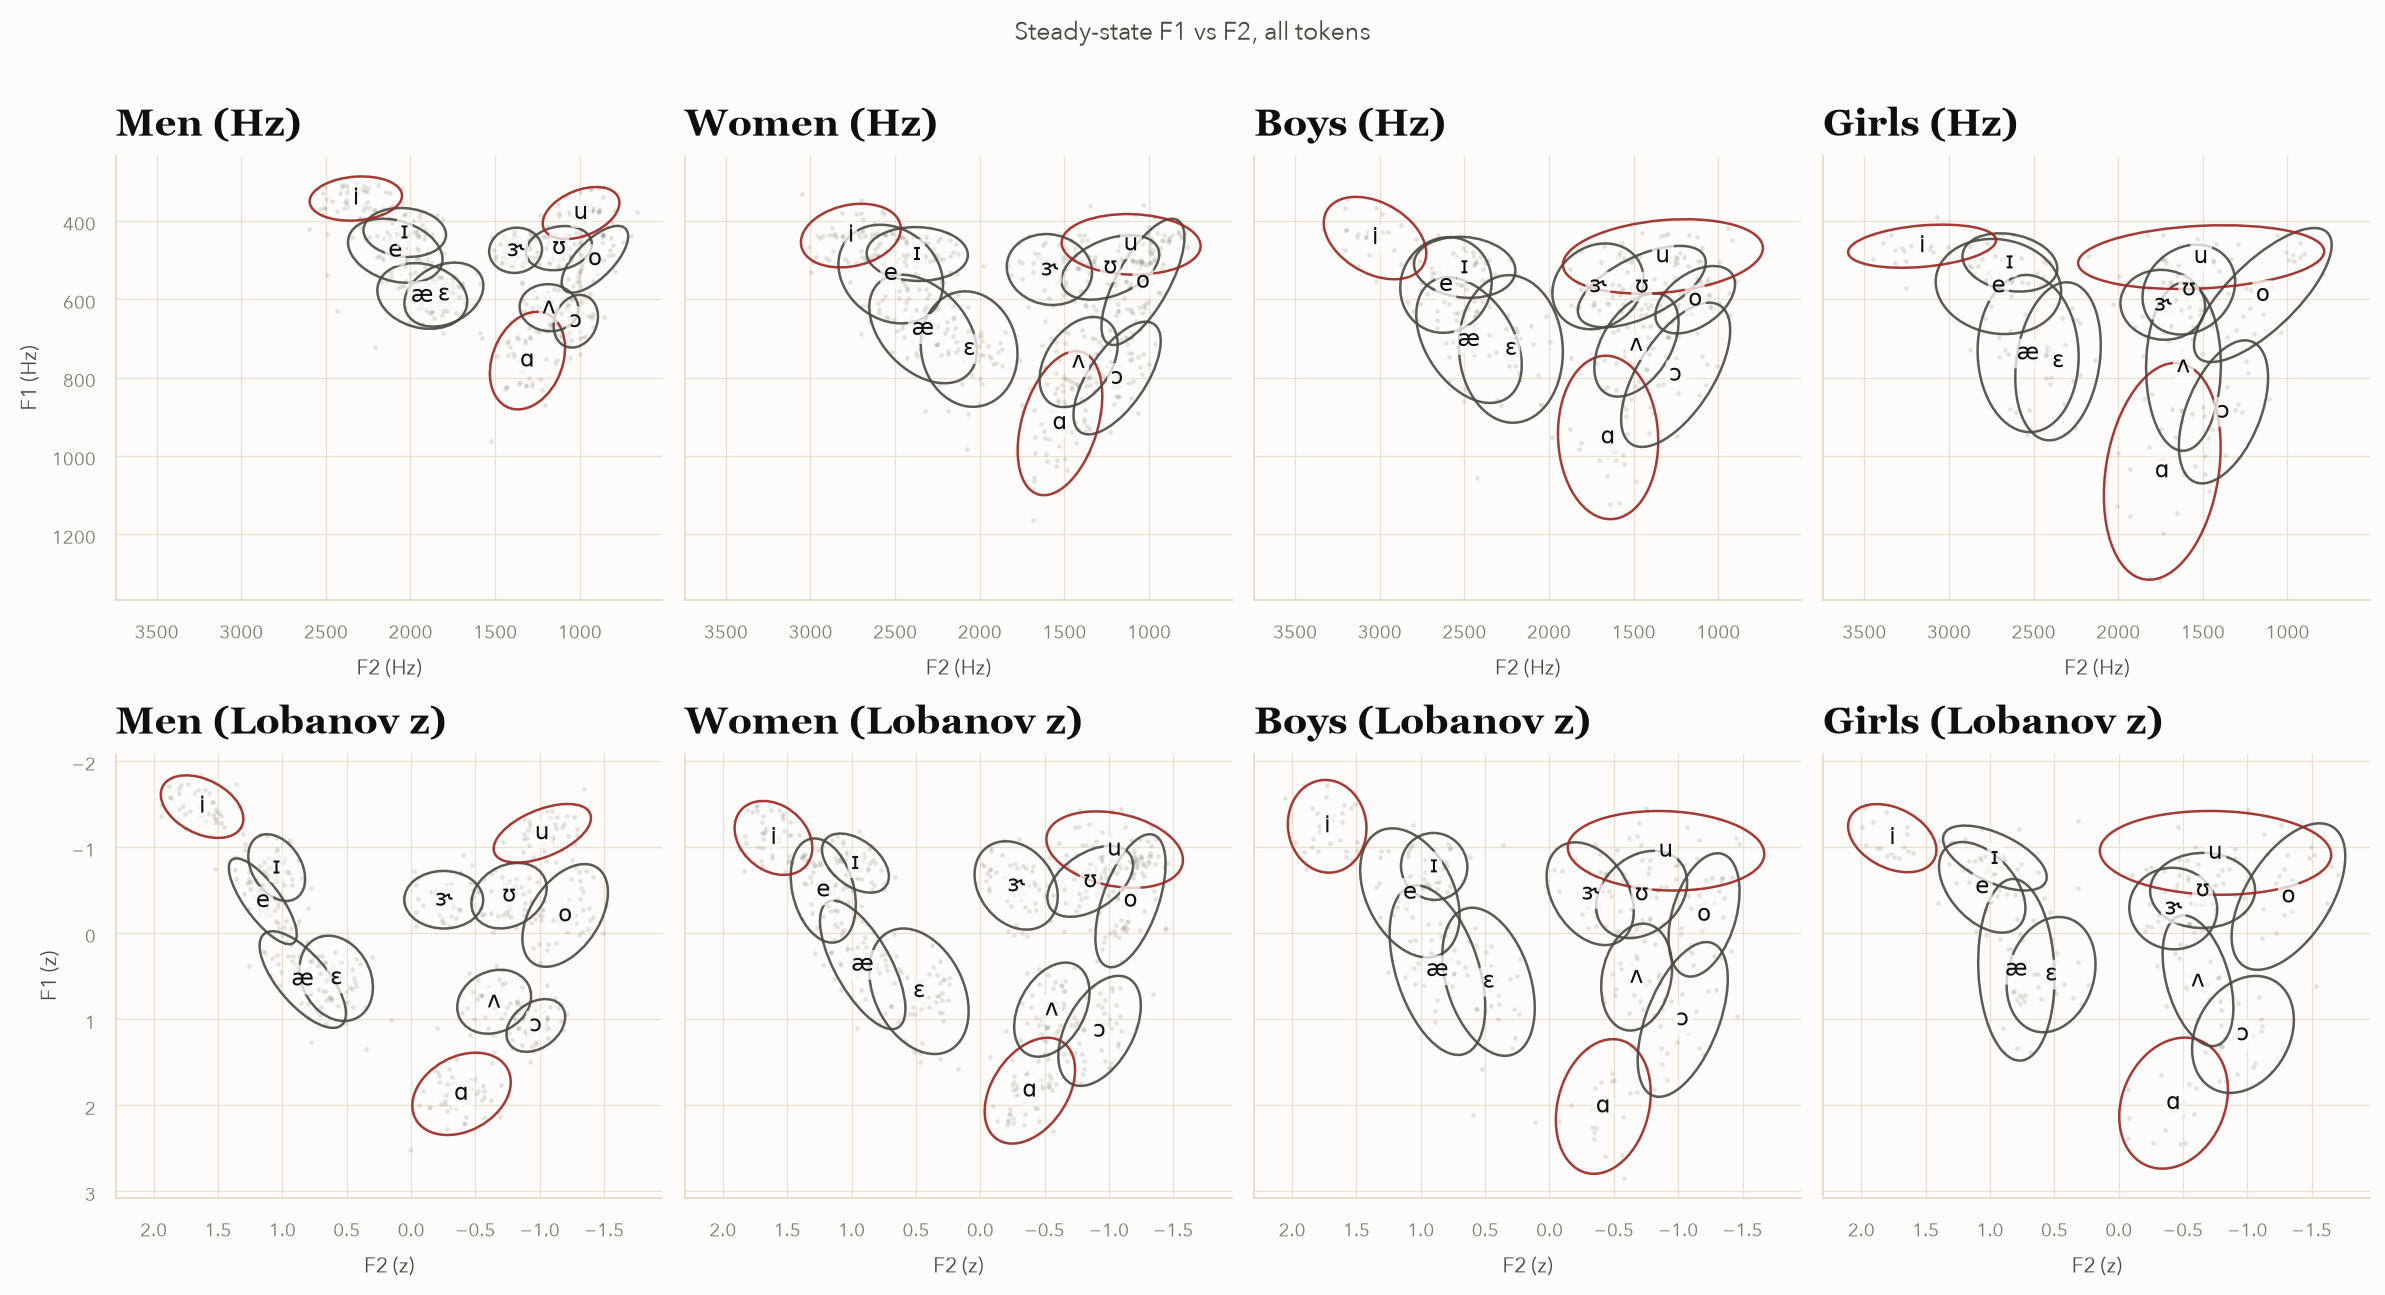

In [217]:
plot_vowel_grid(df)

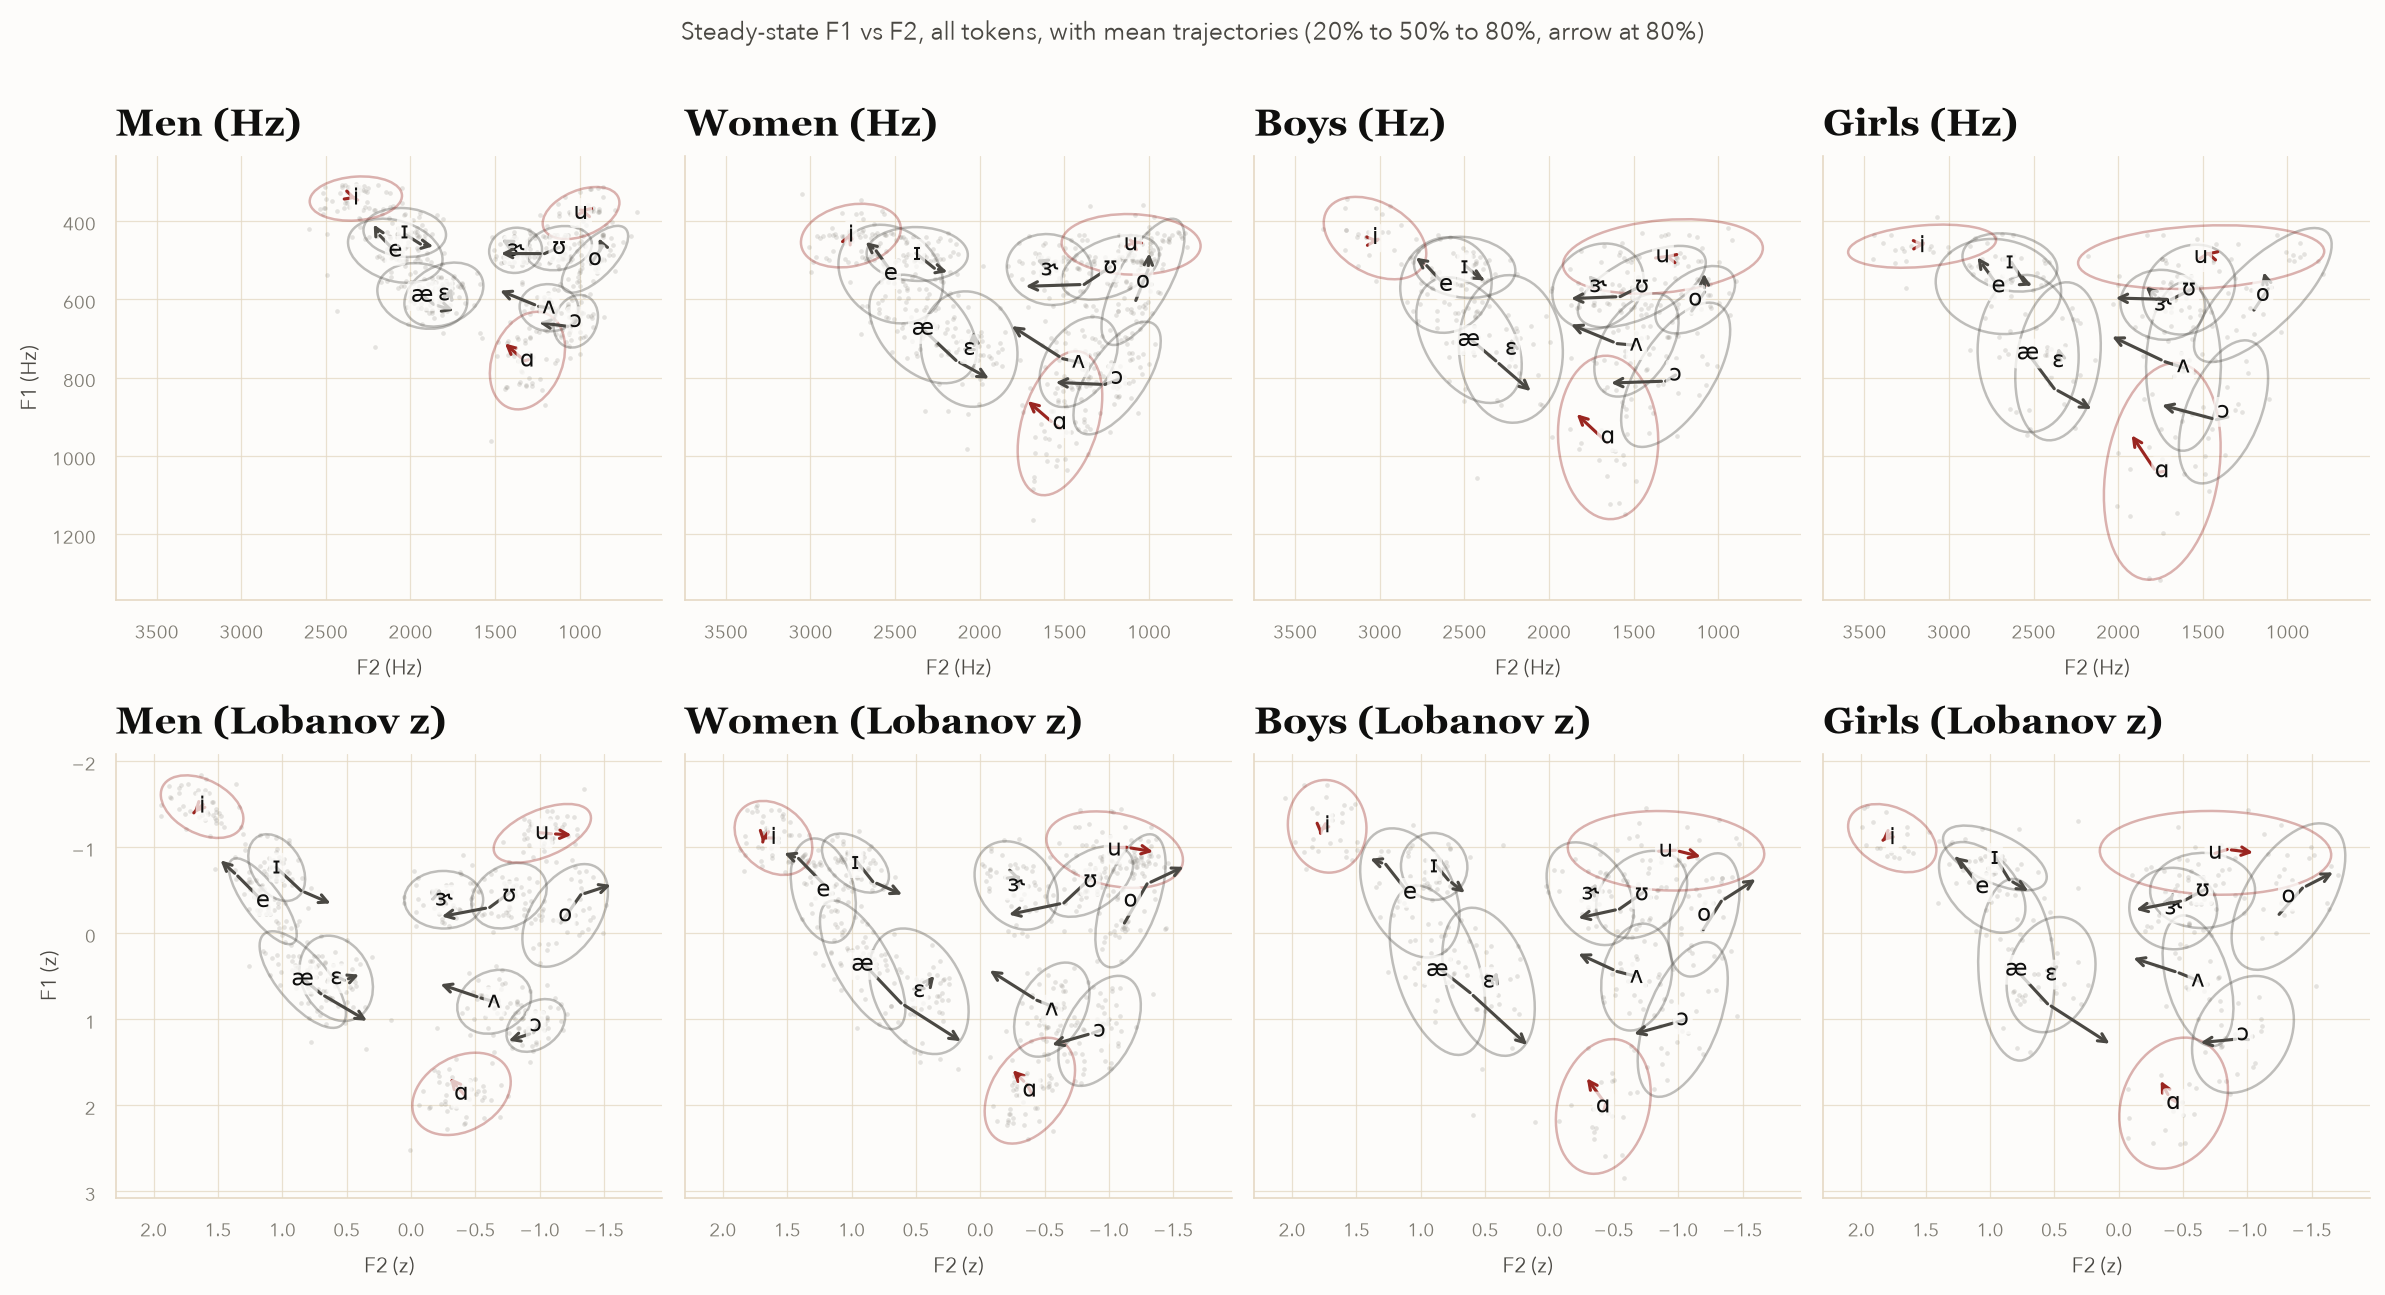

In [218]:
plot_vowel_grid(df, trajectory=True)

Here, we include the formant trajectory data to show the direction in which frequencies move as each vowel develops.

### Mel & Bark Scales

Because Lobanov normalization computes a z-score, we need $\mu$ and $\sigma$ for each speaker's vowel space; in other words, we need a full distribution for each individual. This is sometimes a prohibitive requirement; in those cases, a speaker-intrinsic method can be used, instead.

The [Bark](https://en.wikipedia.org/wiki/Bark_scale) and [Mel](https://en.wikipedia.org/wiki/Mel_scale) scales are psychoacoustic, log-based transformations that map frequencies into buckets designed to reflect human pitch perception.

The details aren't critical; the point is, they convert raw frequencies into a scale that better reflects the fact that human hearing is closer to linear at lower frequencies, and logarithmic as pitch increases. 

Both scales are common. For our tabular classifiers, we'll use Lobanov normalization instead. But for the CNN, we'll generate Mel spectrograms by computing Mel transforms on our STFT results, and generating spectrograms out of these.

Relative to the "raw" spectrograms we inspected above, Mel spectrograms feature a more condensed dynamic range, due to the intrinsic log transform.

In [219]:
def plot_mel_spectrogram(audio, window_duration: float = 0.005, sr: int = 16000, title: str = 'Mel Spectrogram (dB)'):
    win_length = int(window_duration * sr)
    hop_length = win_length // 4
    # 1. Compute Mel spectrogram; n_fft=512 zero-pads short windows (n_fft=80 leaves 61/128 Mel filters empty)
    M = lb.feature.melspectrogram(y=audio, sr=sr, n_fft=512, win_length=win_length, hop_length=hop_length)
    # 2. Convert power to decibels
    S_db = lb.power_to_db(M, ref=np.max)
    
    # plot results
    fig, ax = plt.subplots()
    img = lb.display.specshow(
        S_db,
        sr=sr,
        hop_length=hop_length,
        x_axis='time',
        y_axis='mel', # 3. Update y-axis scale to Mel
        ax=ax,
    )
    fig.colorbar(img, ax=ax, format='%+2.f dB')
    plt.title(title)
    return fig, ax

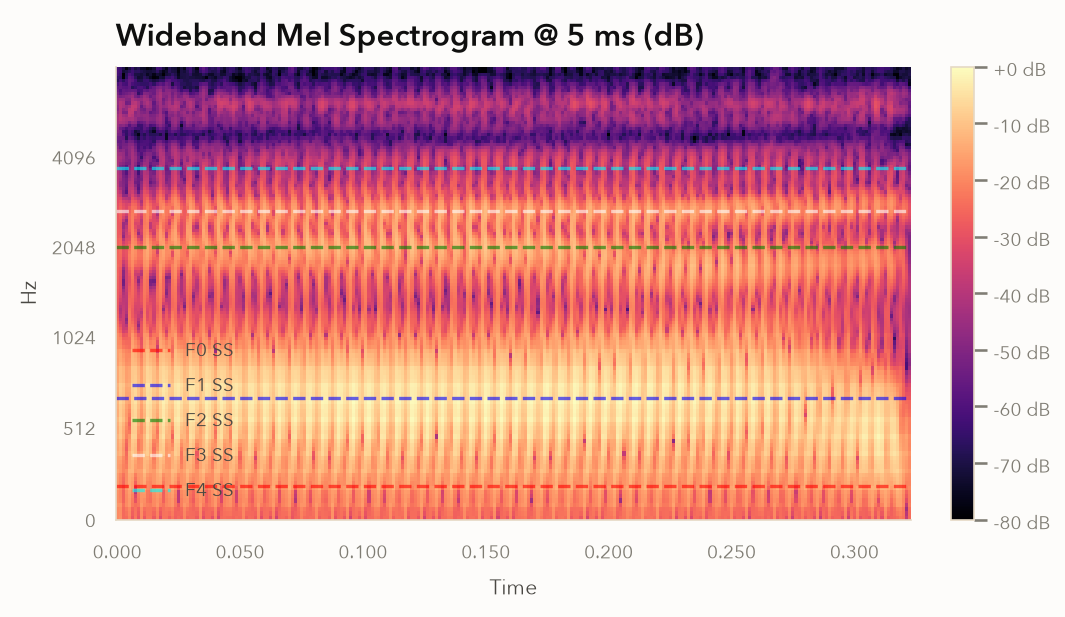

In [220]:
_, ax = plot_mel_spectrogram(audio_, 0.005, sample_rate, title='Wideband Mel Spectrogram @ 5 ms (dB)')

colnames = ['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']
f_ss = zip(['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss'], zip(df.iloc[0][colnames], ['r', 'b', 'g', 'white', 'cyan']))
for colname, (ss, color) in f_ss:
    ax.axhline(y=ss, linestyle='--', color=color, label=colname.upper().replace('_', ' '), alpha=0.6)

plt.legend()
plt.show()

Note that this has comparable structure, with less "empty space" between regions of interest.

This gives us everything we need to:

- Train classical classifiers on the tabular formant frequency data;
- Generate Mel spectrograms for the CNN.

The cells below do final cleanup on the Lobanov-transformed data to remove NaNs, unnecessary columns, etc.

In [221]:
# generated (Claude): model-ready table.
# Target: intended vowel. Listener vote and misid kept for evaluation only.
df = lobanov(df, ['duration_ms'])  # duration z-scored per speaker: speaking rate varies by speaker
lbnv_cols = [f'{c}_lbnv' for c in formant_cols] + ['duration_ms_lbnv']

# NaN policy: missing z-score -> 0 (the speaker's own mean), plus a 0/1 flag per formant column
z = df[lbnv_cols].fillna(0.0)
missing = df[formant_cols].isna().astype(float).add_suffix('_missing')
missing = missing.loc[:, missing.any()]  # F1 is never missing; drop its all-zero flags
missing = missing.T.drop_duplicates().T  # f2_ss_missing == f2_20_missing on all 1668 rows; keep one

VOWELS = sorted(vowels_map)  # fixed class order: index i <-> VOWELS[i]
data = pd.concat([df[['filename', 'speaker_id', 'category', 'vowel']], z, missing], axis=1)
data['label'] = pd.Categorical(data['vowel'], categories=VOWELS).codes
data['vote'] = y_vote.to_numpy()
data['misid'] = data['vote'] != data['vowel']

feature_cols = lbnv_cols + list(missing.columns)
print(f'{len(data)} rows, {len(feature_cols)} features, '
      f'{data[feature_cols].isna().sum().sum()} NaNs, {data["misid"].sum()} misidentified by listeners')
data.head()

1668 rows, 20 features, 0 NaNs, 33 misidentified by listeners


,filename,speaker_id,category,vowel,f1_ss_lbnv,f1_20_lbnv,f1_50_lbnv,f1_80_lbnv,f2_ss_lbnv,f2_20_lbnv,...,f2_ss_missing,f2_50_missing,f2_80_missing,f3_ss_missing,f3_20_missing,f3_50_missing,f3_80_missing,label,vote,misid
0,m01ae,m01,m,ae,0.812588,0.861108,0.793829,1.226249,0.852310,0.836824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,ae,False
1,m02ae,m02,m,ae,0.898831,0.974623,1.006032,0.991936,0.728691,0.758366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,ae,False
2,m03ae,m03,m,ae,0.708748,0.758972,0.770442,0.969317,0.779574,0.725827,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,ae,False
3,m04ae,m04,m,ae,0.514505,0.468054,0.971005,1.348148,0.814267,0.761383,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,ae,False
4,m06ae,m06,m,ae,0.649385,0.623537,0.737621,1.205424,0.722238,0.747420,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,ae,False


## References


1. J. Hillenbrand, L. A. Getty, M. J. Clark, and K. Wheeler, "Acoustic characteristics of American English vowels," J. Acoust. Soc. Am., vol. 97, no. 5, pt. 1, pp. 3099–3111, May 1995, doi: 10.1121/1.411872.
2. G. E. Peterson and H. L. Barney, "Control methods used in a study of the vowels," J. Acoust. Soc. Am., vol. 24, no. 2, pp. 175–184, Mar. 1952, doi: 10.1121/1.1906875.
3. P. Ladefoged and K. Johnson, A Course in Phonetics, 6th ed. Boston, MA: Wadsworth, 2011.
4. B. H. Story and K. Bunton, "Formant measurement in children's speech based on spectral filtering," Speech Commun., vol. 76, pp. 93–111, Feb. 2016, doi: 10.1016/j.specom.2015.11.001.
5. P. Ladefoged and D. E. Broadbent, “Information conveyed by vowels,” The Journal of the Acoustical Society of America, vol. 29, no. 1, pp. 98–104, Jan. 1957. doi:10.1121/1.1908694 
6. Barlaz, M. (n.d.). Vowel Normalization in R. Marissa Barlaz, PhD. https://marissabarlaz.github.io/portfolio/vowelnormalization/#what-is-vowel-normalization
7. Harris, F. J., "On the use of windows for harmonic analysis with the discrete Fourier transform," *Proc. IEEE*, vol. 66, no. 1, pp. 51–83, 1978.
8. P. Adank, R. van Hout, and R. Smits, "An acoustic description of the vowels of Northern and Southern Standard Dutch," J. Acoust. Soc. Amer., vol. 116, no. 3, pp. 1729–1738, Sep. 2004, doi: 10.1121/1.1779271
9. W. Heeringa and H. Van de Velde, "A new vowel normalization for sociophonetics," in *Proc. Interspeech 2021*, Brno, Czechia, Aug. 2021, pp. 4024–4028, doi: 10.21437/Interspeech.2021-1846.

**Further reading**

- W. Rankinen and K. de Jong, "The entanglement of dialectal variation and speaker normalization," *Lang. Speech*, vol. 64, no. 1, pp. 181–202, Mar. 2021, doi: 10.1177/0023830920929379.
- B. Ghojogh and M. Crowley, "Linear and quadratic discriminant analysis: Tutorial," arXiv:1906.02590.
